# Can guided LLM search invent bin-packing rules? (NOV-B2, run 2): demo

**NOV-B2** runs a **FunSearch-style island search** for **online bin packing**. The mutator is **Qwen3-8B-FP8**
(vLLM 0.11, thinking off), and it rewrites Python `priority(item, bins)` functions. The question is *where the
sampling randomness should be spent*. Six arms run at matched calls, 2,000 calls per arm and seed:

| arm | what it does |
|---|---|
| `T1.0` | temperature 1.0 |
| `T1.6` | temperature 1.6 with top-p 0.95 |
| `DTB` | **decision-token branching**: force a rank-2..8 token at the highest-entropy eligible position among the first 48 body tokens |
| `RPB` | the same forcing at a *random* eligible position (the placebo for DTB) |
| `IDEA` | one extra sentence in the prompt: *"Write priority_v2 based on an idea different from both functions above."* |
| `NS` | no selection: fixed FF/BF parents (the random-sampling baseline) |

**Headline results of the full run** (pre-registered, seeds 2-3, 22,000 logged LLM calls):
- **Temperature is not a creativity knob here.** T1.6 with top-p 0.95 is effectively greedy: it produces one behaviour
  in 4,000 calls. T1.0 copies its parent 96 % of the time.
- **Forcing pays; choosing the position does not.** DTB, its random-position placebo RPB and the IDEA instruction find
  7-18x more behaviour clusters than temperature, and better held-out heuristics. Picking the forced position by
  entropy is no better than picking it at random (R_RPB = 0.74).
- **No new rules.** 48 candidates beat 0.8 x best fit and are novel against the corpus at the behaviour level. All 40
  judged candidates recombine published principles (V3 disconfirmed).

**What this notebook runs.** It runs the CPU parts of the pipeline, on 96 logged calls and with the original code
from `src/` (file I/O is replaced by in-memory data):
1. **S0/S1 harness gate.** FunSearch's exact harness, which reproduces FunSearch's printed numbers.
2. **S2 probes.** The 2,000 committed probe states (P10) are rebuilt, and their sha256 is checked against the commitment.
3. **S3 corpus.** Textbook rules, FunSearch's c12/c14, the ab family and the tuned ab baseline.
4. **Search stage, re-derived from the logs.** The exact prompts (sha256-checked), the extraction of programs from
   completions, and the DTB/RPB branch plans recomputed from the logged top-20 log-prob tables.
5. **Evaluation of the logged programs.** The sandbox gives validity, selection fitness F and P10 behaviour vectors.
6. **S10 analysis.** Behaviour clusters (complete linkage at 0.95), rename share (V6), each arm's best program.
7. **Held-out scoring.** V1's 0.8 x BF rule, plus the corpus-novelty filter (step 2 of V3).

**What it does not run.** The LLM generation needs vLLM on a 24 GB GPU (about 1 h for 42,000 calls). The LLM
judges need an API, and the V5 teacher-forcing test needs the GPU. Everything that can be derived from the
logged calls is recomputed here and compared with the logged values.

`mini_demo_data.json` holds 96 calls from the `novb2_search_programs` dataset. For each arm it has the arm's best
program and 15 calls drawn at random from the matched window (calls 0-199 of seeds 2 and 3).

| `method.py` stage | original modules | in this notebook |
|---|---|---|
| `setup` | `s0_setup.py`, `gate.py`, `bp.py`, `sandbox.py` | harness and G-HARNESS numbers re-derived |
| `probes` | `probes.py` | P10 rebuilt, sha256 checked, probe gate |
| `corpus` | `corpus.py` | textbook + FunSearch + ab-family subset, tuned ab, stateful baselines |
| `engine`, `smoke`, `search`, `extension` | `engine.py`, `prompts.py`, `operators.py`, `islands.py`, `search.py` | needs the GPU. Prompts and branch plans are re-derived from the logs, and the logged programs are re-evaluated |
| `analysis` | `analysis.py`, `clusters.py` | clusters, rename share and best programs on the sample |
| `heldout` | `heldout.py` | held-out scoring of each arm's best, the V1 rule and the novelty filter |
| `s3b`, `judges`, `v5`, `hfreplay` | `judges.py`, `v5.py`, `hfreplay.py` | not run (web scan, API judges, GPU) |
| `verdicts`, `figures` | `analysis.py`, `figures.py` | summary table and figures at the end |

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru — NOT on Colab, always install (the original modules log with loguru)
_pip('loguru==0.7.3')

# numpy, scipy, matplotlib, transformers (tokenizer only), tokenizers, huggingface_hub — pre-installed on Colab, install locally only
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'matplotlib==3.10.0', 'transformers==5.0.0', 'tokenizers==0.22.2',
         'huggingface_hub==1.4.0')

In [2]:
from __future__ import annotations

import ast
import hashlib
import io
import json
import keyword
import math
import os
import re
import signal
import sys
import time
import tokenize
import types
from pathlib import Path
from typing import Any, Callable

os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
os.environ.setdefault("MKL_NUM_THREADS", "1")

import numpy as np
from loguru import logger
from scipy.cluster.hierarchy import fcluster, linkage
from scipy.sparse import csr_matrix
from scipy.spatial.distance import squareform

# notebook additions: plots and the %%module cell magic below
import matplotlib.pyplot as plt
from IPython.core.magic import register_cell_magic

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_jSassd-YWLVC/round-10/experiment-52/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
EXAMPLES = data["examples"]
print(data["description"])
print(f"{len(EXAMPLES)} logged calls from dataset {data['source_dataset']!r}; top-level keys: {list(data)}")

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
NOV-B2 demo subset: 96 logged LLM calls from the novb2_search_programs dataset (seeds 2-3); per arm the best program plus 15 calls sampled from the matched window calls 0-199.
96 logged calls from dataset 'novb2_search_programs'; top-level keys: ['description', 'source_dataset', 'selection', 'examples', 'harness_inputs', 'logged']


## Configuration

The demo-scale knobs are below, and the values of the full run are in the comments. They are set to the largest
values the shipped data supports: all 96 logged calls, all 30 logged DTB/RPB top-20 tables, every 10th ab member and
25 tuned-ab evaluations. With these values the whole notebook runs in about 3 minutes on one CPU core. The
smallest values that still produce every output are `N_PER_ARM = 1`, `N_PROMPTS = 6`, `N_BRANCH_REDERIVE = 1`,
`AB_STRIDE = 400` and `N_TUNE_EVALS = 1`, which take under 2 minutes.

The protocol constants (the 0.95 cluster threshold, the 0.9 novelty threshold, the 20 s CPU budgets, the 0.8 x BF
rule) were frozen by the pre-registration. They stay inside the original module code below and are not demo knobs.

In [5]:
# ---- demo scale (the original values are in the comments) ----
N_PER_ARM = 15           # matched-window calls evaluated per arm, of the 15 shipped per arm (original: all 2,000 calls per arm-seed)
N_PROMPTS = 96           # logged calls whose prompt is rebuilt and sha256-checked, of the 96 shipped (original: every call)
N_BRANCH_REDERIVE = 15   # DTB and RPB calls each whose branch plan is re-derived from the logged top-20 tables (original: 200 per arm-seed)
AB_STRIDE = 10           # every AB_STRIDE-th member of the 3,843-member ab grid enters the corpus (original: 1 = all members)
N_TUNE_EVALS = 25        # ab members scored by the tuned-ab random search, in the committed permutation order (original: 2,000)
HELDOUT_SETS = ["H-FSW5k", "H-OR3"]  # the two primary held-out sets, both required by V1 (original: + H-W5k, H-W10k, H-SHIFT, H-OR1, H-OR2, H-OR4)

### Notebook infrastructure: keep the original modules verbatim

The original code is a set of modules in `src/` that import each other (`import bp`, `import clusters as CL`,
`import common as C`, ...). The cell magic below keeps that code unchanged. A cell that starts with
`%%module NAME` runs as the source of a module `NAME`. The module is registered in `sys.modules`, so later
modules can import it as in the repository. The logger gets the stdout sink of `common.setup_logging` (its file
sink is dropped).

In [6]:
logger.remove()
logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")


@register_cell_magic
def module(line, cell):
    """`%%module NAME`: run the cell as the source of module NAME, register it in sys.modules (so that later modules
    can `import NAME`, as the src/ modules import each other) and bind NAME in the notebook namespace."""
    name = line.split()[0]
    mod = types.ModuleType(name)
    sys.modules[name] = mod
    exec(compile(cell, f"<{name}>", "exec"), mod.__dict__)
    get_ipython().user_ns[name] = mod

## Stage `setup` (S0/S1): the exact FunSearch harness

`src/common.py` holds the shared constants. Only the constants and hashing helpers are needed here. Its workspace
paths, log sinks, JSONL helpers, time ledger and status files are left out.

In [7]:
%%module common
"""Shared helpers (subset of src/common.py): constants and hashing."""
from __future__ import annotations

import hashlib
import time

ENGINE_TAG = "vllm0.11.0|Qwen3-8B-FP8@220b46e|fp8-marlin-w8a16|RTX4090"
MODEL_ID = "Qwen/Qwen3-8B-FP8"
MODEL_REV = "220b46e3b2180893580a4454f21f22d3ebb187d3"
SERVED_NAME = "qwen3-8b"

ARM_IDS = {"T1.0": 0, "T1.6": 1, "DTB": 2, "RPB": 3, "IDEA": 4, "NS": 5}
CORE_ARMS = ["T1.0", "T1.6", "DTB", "RPB"]
SEEDS = [2, 3]


def utc() -> str:
    return time.strftime("%Y-%m-%dT%H:%M:%SZ", time.gmtime())


def sha256_bytes(b: bytes) -> str:
    return hashlib.sha256(b).hexdigest()


def sha256_text(s: str) -> str:
    return hashlib.sha256(s.encode()).hexdigest()

`src/bp.py` is the harness. It follows the semantics of FunSearch's `bin_packing.ipynb`. Bins are pre-allocated
(one per item, all at full capacity). `priority(item, bins[valid])` scores every bin that fits, unused bins
included. The item goes to `valid[np.argmax(priorities)]`, so ties go to the first index. The score is the number
of bins used. A family of instances is scored by its **excess** over the L1 lower bound:
`(mean bins - mean L1) / mean L1`. The selection fitness `F` averages the excess on the two selection sets
(SEL-OR, SEL-W), each normalised by best fit's excess. So `F(BF) = 1`, and lower is better.

Two notebook changes: the instance sets and the FunSearch notebook contents (its OR3 and Weibull 5k test data, and
its two discovered heuristics c12 and c14) are read from memory, and `build_all_sets` drops OR-Library
binpack1/2/4, which the demo does not ship.

In [8]:
%%module bp
"""Exact FunSearch online bin-packing harness, instance sets, textbook/published heuristics and selection fitness.

Semantics copied from google-deepmind/funsearch bin_packing.ipynb (commit 2a2c864):
bins are pre-allocated (one per item, all at full capacity, int dtype); priority(item, bins[valid]) scores every
bin that fits (unused bins included); the item goes to valid[np.argmax(priorities)] (first index on ties, first NaN
if any NaN); score = number of bins whose remaining capacity != capacity.
"""
from __future__ import annotations

import ast
import hashlib
import json
import math
from typing import Callable

import numpy as np

# notebook: instance sets and the parsed FunSearch notebook live in memory (filled from mini_demo_data.json) instead
# of data/instances/*.json and ext/funsearch/bin_packing.ipynb
SETS: dict[str, list[dict]] = {}
FUNSEARCH_NB: dict = {}


class ShapeError(Exception):
    """Priority output is not a 1-D array with one score per valid bin."""


class NonFiniteError(Exception):
    """Priority output contains NaN or +-inf (invalid under the iteration-10 validity rule, protocol v10)."""


# ----------------------------------------------------------------------------------------------- harness
def valid(item: int, bins: np.ndarray) -> np.ndarray:
    return np.nonzero((bins - item) >= 0)[0]


def _finite_or_raise(p: np.ndarray) -> None:
    if p.dtype.kind not in "biuf":
        p = p.astype(np.float64)  # non-numeric output raises here (runtime error)
    if p.dtype.kind == "f" and not np.isfinite(p).all():
        raise NonFiniteError("priority returned a non-finite score")


def pack(items: list[int], cap: int, prio: Callable, strict: bool = False, nf_counter: list | None = None) -> int:
    """Pack `items` online with FunSearch semantics; return the number of used bins.

    strict=True applies the v10 validity rule (every score finite, else NonFiniteError). With strict=False
    (FunSearch semantics) non-finite scores are tolerated and, if `nf_counter` is given, counted in nf_counter[0]."""
    bins = np.array([cap for _ in range(len(items))])
    for it in items:
        v = np.nonzero(bins >= it)[0]  # identical to (bins - item) >= 0 for integer data
        p = np.asarray(prio(it, bins[v]))
        if p.ndim != 1 or p.shape[0] != v.shape[0]:
            raise ShapeError(f"priority returned shape {p.shape} for {v.shape[0]} valid bins")
        if strict:
            _finite_or_raise(p)
        elif nf_counter is not None and p.dtype.kind == "f" and not np.isfinite(p).all():
            nf_counter[0] += 1
        b = v[np.argmax(p)]
        bins[b] -= it
    return int((bins != cap).sum())


def pack_trace(items: list[int], cap: int, prio: Callable) -> tuple[int, list[tuple[int, list[int], int, int]]]:
    """Pack and record states: (item, remaining caps of opened bins that fit in index order, n_empty, chosen cap)."""
    n = len(items)
    bins = np.array([cap for _ in range(n)])
    used = np.zeros(n, dtype=bool)
    states = []
    for it in items:
        v = np.nonzero(bins >= it)[0]
        vb = bins[v]
        p = np.asarray(prio(it, vb))
        b = v[np.argmax(p)]
        opened_fit = [int(x) for x, u in zip(vb, used[v]) if u]
        n_empty = int((~used).sum())
        states.append((int(it), opened_fit, n_empty, int(bins[b])))
        bins[b] -= it
        used[b] = True
    return int(used.sum()), states


def l1(items: list[int], cap: int) -> int:
    return int(math.ceil(sum(items) / cap))


def family_excess(bins: list[int] | np.ndarray, l1s: list[int] | np.ndarray) -> float:
    """FunSearch's excess: (mean bins - mean L1) / mean L1 over a family of instances."""
    mb, ml = float(np.mean(bins)), float(np.mean(l1s))
    return (mb - ml) / ml


# ----------------------------------------------------------------------------------------------- instances
def weibull_items(rng: np.random.Generator, n: int, shape: float = 3.0, scale: float = 45.0, hi: int = 100) -> list[int]:
    x = np.clip(np.round(rng.weibull(shape, size=n) * scale), 1, hi).astype(int)
    return [int(v) for v in x]


def uniform_items(rng: np.random.Generator, n: int, lo: int = 20, hi: int = 100) -> list[int]:
    return [int(v) for v in rng.integers(lo, hi + 1, size=n)]


def _inst(name: str, cap: int, items: list[int]) -> dict:
    return {"id": name, "capacity": int(cap), "num_items": len(items), "items": items, "l1": l1(items, cap)}


def gen_sets() -> dict[str, list[dict]]:
    """All generated instance sets (seeds fixed in the plan)."""
    s: dict[str, list[dict]] = {}
    s["SEL-OR"] = [_inst(f"selor_{i}", 150, uniform_items(np.random.default_rng(91001 + i), 120)) for i in range(20)]
    s["SEL-W"] = [_inst(f"selw_{i}", 100, weibull_items(np.random.default_rng(92001 + i), 5000)) for i in range(5)]
    s["H-W5k"] = [_inst(f"hw5k_{i}", 100, weibull_items(np.random.default_rng(93001 + i), 5000)) for i in range(5)]
    s["H-W10k"] = [_inst(f"hw10k_{i}", 100, weibull_items(np.random.default_rng(94001 + i), 10000)) for i in range(5)]
    s["H-SHIFT"] = [_inst(f"hshift_{i}", 150, weibull_items(np.random.default_rng(97001 + i), 5000, 7.0, 75.0, 150))
                    for i in range(5)]
    s["CALIB-W"] = [_inst(f"calw_{i}", 100, weibull_items(np.random.default_rng(99001 + i), 5000)) for i in range(20)]
    s["P1SRC-W"] = [_inst(f"p1w_{i}", 100, weibull_items(np.random.default_rng(95001 + i), 5000)) for i in range(5)]
    s["P1SRC-OR"] = [_inst(f"p1or_{i}", 150, uniform_items(np.random.default_rng(96001 + i), 500)) for i in range(5)]
    return s


def funsearch_notebook() -> tuple[dict, dict, str, str]:
    """Return (OR3 dict, Weibull 5k dict, OR heuristic source, Weibull heuristic source) parsed as data.

    notebook: these four values were parsed from ext/funsearch/bin_packing.ipynb exactly as the original does
    (ast.literal_eval of the assignments in cell 2; the text of cells 8 and 9 before '# Test performance') when
    mini_demo_data.json was built; here they are read from FUNSEARCH_NB."""
    d = FUNSEARCH_NB
    return d["OR3"], d["Weibull 5k"], d["or_src"], d["w_src"]


def nb_dict_to_insts(d: dict) -> list[dict]:
    return [_inst(k, v["capacity"], [int(x) for x in v["items"]]) for k, v in d.items()]


def sha_insts(insts: list[dict]) -> str:
    h = hashlib.sha256()
    for x in insts:
        h.update(json.dumps([x["id"], x["capacity"], x["items"]]).encode())
    return h.hexdigest()


def build_all_sets() -> dict[str, list[dict]]:
    sets = gen_sets()
    # notebook: OR-Library binpack1/2/4 (H-OR1, H-OR2, H-OR4) are not shipped with the demo. binpack3 (H-OR3) equals
    # the FunSearch notebook's OR3 item for item (gate check binpack3_equals_notebook_OR3), so it is rebuilt from it.
    or3, w5k, _, _ = funsearch_notebook()
    sets["H-OR3"] = nb_dict_to_insts(or3)
    sets["FS-OR3"] = nb_dict_to_insts(or3)
    sets["H-FSW5k"] = nb_dict_to_insts(w5k)
    return sets


def load_set(name: str) -> list[dict]:
    return SETS[name]  # notebook: in memory (was json.loads((INST_DIR / f"{name}.json").read_text()))


# ----------------------------------------------------------------------------------------------- heuristics
def prio_ff(item, bins):
    return -np.arange(len(bins))


def prio_bf(item, bins):
    return -(bins - item)


def prio_wf(item, bins):
    score = (bins - item).astype(float)
    m = bins == bins.max()
    if not m.all():
        score[m] = -1e9
    return score


def prio_c12_vec(item, bins):
    """Vectorised exact equivalent of FunSearch's OR heuristic (c12)."""
    g = bins - item
    return np.select([g <= 2, g <= 3, g <= 5, g <= 7, g <= 9, g <= 12, g <= 15, g <= 18, g <= 20, g <= 21],
                     [4, 3, 2, 1, 0.9, 0.95, 0.97, 0.98, 0.98, 0.98], 0.99)


def prio_c14(item, bins):
    max_bin_cap = max(bins)
    score = (bins - max_bin_cap) ** 2 / item + bins ** 2 / (item ** 2)
    score += bins ** 2 / item ** 3
    score[bins > item] = -score[bins > item]
    score[1:] -= score[:-1]
    return score


def prio_awf(item, bins):
    """Almost-worst fit in priority form: the second-largest remaining capacity among opened bins that fit (the
    largest if only one fits); a new bin only when no opened bin fits."""
    cap = bins.max()
    op = np.nonzero(bins < cap)[0]
    score = np.zeros(len(bins))
    if len(op) == 0:
        return score
    order = op[np.argsort(-bins[op], kind="stable")]
    score[op] = 1.0
    score[order[1] if len(order) >= 2 else order[0]] = 2.0
    return score


SRC_AWF = ("def priority(item, bins):\n    cap = bins.max()\n    op = np.nonzero(bins < cap)[0]\n"
           "    score = np.zeros(len(bins))\n    if len(op) == 0:\n        return score\n"
           "    order = op[np.argsort(-bins[op], kind='stable')]\n    score[op] = 1.0\n"
           "    score[order[1] if len(order) >= 2 else order[0]] = 2.0\n    return score\n")


def next_fit(items: list[int], cap: int) -> int:
    """Next Fit (standalone, stateful): only the most recently opened bin is open."""
    used, rem = 0, -1
    for s in items:
        if rem < s:
            used += 1
            rem = cap
        rem -= s
    return used


def make_ab(a: int, b: int, base: str) -> Callable:
    """ab-heuristics of Herrmann & Pallez (arXiv 2510.27353, Algorithms 4-6); capacity = bins.max() (an unused bin
    at full capacity is always among the valid bins in the pre-allocated harness)."""
    def prio(item, bins):
        cap = bins.max()
        with np.errstate(divide="ignore", invalid="ignore"):
            first = cap - bins + 1
            if base == "FF":
                return np.where(bins <= item + a, first, np.where(bins < item + b, -2, 1))
            if base == "BF":
                return np.where(bins <= item + a, first, np.where(bins < item + b, -2.0, 1.0 / (bins - item)))
            return np.where(bins <= item + a, first, np.where(bins <= item + b, -2.0,
                                                              np.where(bins == cap, -1.0, -1.0 / (bins - item))))
    prio.__name__ = f"ab{base}_{a}_{b}"
    return prio


def ab_source(a: int, b: int, base: str) -> str:
    """Program text of an ab member in the search's program format (for probes/corpus)."""
    if base == "FF":
        tail = "np.where(bins < item + b, -2, 1)"
    elif base == "BF":
        tail = "np.where(bins < item + b, -2.0, 1.0 / (bins - item))"
    else:
        tail = "np.where(bins <= item + b, -2.0, np.where(bins == cap, -1.0, -1.0 / (bins - item)))"
    return (f"def priority(item, bins):\n    a, b = {a}, {b}\n    cap = bins.max()\n"
            f"    with np.errstate(divide='ignore', invalid='ignore'):\n"
            f"        return np.where(bins <= item + a, cap - bins + 1, {tail})\n")


SRC_FF = "def priority(item, bins):\n    return -np.arange(len(bins))\n"
SRC_BF = "def priority(item, bins):\n    return -(bins - item)\n"
SRC_WF = ("def priority(item, bins):\n    score = (bins - item).astype(float)\n    m = bins == bins.max()\n"
          "    if not m.all():\n        score[m] = -1e9\n    return score\n")


def harmonic_k(items: list[int], cap: int, k: int) -> int:
    """Lee & Lee Harmonic-k (standalone, stateful): class j<k items (cap/(j+1) < s <= cap/j) packed j per bin;
    class-k items (s <= cap/k) packed by Next Fit in their own bins."""
    count = {j: 0 for j in range(1, k)}
    bins_used = 0
    nf_rem = None
    for s in items:
        j = next((j for j in range(1, k) if s * (j + 1) > cap and s * j <= cap), k)
        if j < k:
            if count[j] == 0:
                bins_used += 1
            count[j] = (count[j] + 1) % j
        else:
            if nf_rem is None or nf_rem < s:
                bins_used += 1
                nf_rem = cap
            nf_rem -= s
    return bins_used


# ----------------------------------------------------------------------------------------------- fitness
class Fitness:
    """F = 0.5*exc_OR/exc_OR(BF) + 0.5*exc_W/exc_W(BF) on the 25 selection instances (lower is better, F(BF)=1)."""

    def __init__(self, sel_or: list[dict], sel_w: list[dict], bf_or_exc: float, bf_w_exc: float):
        self.l1_or = [x["l1"] for x in sel_or]
        self.l1_w = [x["l1"] for x in sel_w]
        self.n_or = len(sel_or)
        self.bf_or_exc, self.bf_w_exc = bf_or_exc, bf_w_exc

    def parts(self, bins25: list[int]) -> tuple[float, float]:
        return family_excess(bins25[:self.n_or], self.l1_or), family_excess(bins25[self.n_or:], self.l1_w)

    def F(self, bins25: list[int]) -> float:
        eo, ew = self.parts(bins25)
        return 0.5 * eo / self.bf_or_exc + 0.5 * ew / self.bf_w_exc


def eval_set(insts: list[dict], prio: Callable) -> list[int]:
    return [pack(x["items"], x["capacity"], prio) for x in insts]

Build every instance set. The generated sets come from fixed numpy seeds. FS-OR3, H-OR3 and H-FSW5k come from
the FunSearch notebook data. Each set's sha256 is compared with the hash logged by the original gate.

In [9]:
import bp

bp.FUNSEARCH_NB.update(data["harness_inputs"]["funsearch_notebook"])
sets = bp.build_all_sets()
bp.SETS.update(sets)
logged = data["logged"]
for name, insts in sets.items():
    print(f"{name:8s} {len(insts):3d} instances x {int(np.mean([x['num_items'] for x in insts])):6d} items   "
          f"sha256 equals the logged set: {bp.sha_insts(insts) == logged['instance_sha256'][name]}")

SEL-OR    20 instances x    120 items   sha256 equals the logged set: True
SEL-W      5 instances x   5000 items   sha256 equals the logged set: True
H-W5k      5 instances x   5000 items   sha256 equals the logged set: True
H-W10k     5 instances x  10000 items   sha256 equals the logged set: True
H-SHIFT    5 instances x   5000 items   sha256 equals the logged set: True
CALIB-W   20 instances x   5000 items   sha256 equals the logged set: True
P1SRC-W    5 instances x   5000 items   sha256 equals the logged set: True
P1SRC-OR   5 instances x    500 items   sha256 equals the logged set: True
H-OR3     20 instances x    500 items   sha256 equals the logged set: True
FS-OR3    20 instances x    500 items   sha256 equals the logged set: True
H-FSW5k    5 instances x   5000 items   sha256 equals the logged set: True


### The sandbox (`src/sandbox.py`)

LLM-written programs are untrusted. Each one goes through an AST screen: imports other than numpy/math, dunder
access, `open`/`exec`/`eval`/... and numpy file I/O are rejected. It is then `exec`'d with restricted builtins and
evaluated under CPU-time budgets (ITIMER_PROF). There is one cumulative 20 s budget over SEL-OR then SEL-W, then a
20 s budget for the P10 probe pass.

Validity rule v10: an output must be 1-D, with one finite score per valid bin. Otherwise the program is classed
`shape` or `nonfinite`. Programs whose only failure is non-finite scores are re-scored once under FunSearch
semantics, as a sensitivity check.

The original runs each task in persistent spawn workers, capped by RLIMIT_AS, with a parent watchdog. Here
`run_task` executes one iteration of the worker loop in-process. The original code has this path too: its probe
gate checks that in-process decisions equal the workers' decisions.

In [10]:
%%module sandbox
"""Subprocess sandbox for LLM-written priority programs: AST screen, restricted exec, CPU-time limits, persistent
workers (spawn) each capped by RLIMIT_AS, a parent watchdog that kills and respawns hung workers.

Iteration-10 changes (diff in results/harness_changes.diff):
- ONE cumulative ITIMER_PROF budget across the selection sets (SEL-OR then SEL-W, fail fast) instead of one per set;
  held-out tasks keep a per-set budget (120 s);
- validity rule v10: strict packing (1-D, one score per valid bin, all scores finite) -> 'shape' / 'nonfinite';
  programs that fail ONLY by non-finite scores are re-scored once under FunSearch semantics (sensitivity);
- probe pass on P10 for valid programs only; a probe timeout marks the remaining states ERR (the vector is kept);
- `stochastic` AST flag and a parent-side result cache keyed by normalise_key (see EvalCache).

notebook: the spawn-worker pool (EvalPool), its pipes, the RLIMIT_AS/RLIMIT_FSIZE caps and the watchdog are not used;
run_task() is one iteration of _worker_main's loop, run in-process."""
from __future__ import annotations

import ast
import hashlib
import math
import os
import time

os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
os.environ.setdefault("MKL_NUM_THREADS", "1")

import numpy as np  # noqa: E402

ALLOWED_MODULES = {"numpy", "math"}
FORBIDDEN_NAMES = {"open", "exec", "eval", "compile", "__import__", "globals", "locals", "vars", "getattr", "setattr",
                   "delattr", "input", "breakpoint"}
# extra I/O layer (not in the plan's list; documented): numpy file/ctypes entry points
FORBIDDEN_ATTRS = {"save", "savez", "savez_compressed", "savetxt", "load", "loadtxt", "fromfile", "tofile", "memmap",
                   "genfromtxt", "fromregex", "ctypeslib", "ctypes", "DataSource", "f2py", "distutils", "testing"}
ERR_CODE = 65535
ERROR_TYPES = ("ok", "syntax", "forbidden", "runtime", "shape", "nonfinite", "timeout", "memory")
SEL_SETS = ["SEL-OR", "SEL-W"]
SEL_BUDGET_S = 20.0
PROBE_BUDGET_S = 20.0
HELDOUT_BUDGET_S = 120.0
SEL_WATCHDOG_S = 90.0


class Forbidden(Exception):
    pass


class CpuTimeout(Exception):
    pass


def screen(tree: ast.AST) -> None:
    """Reject imports other than numpy/math, forbidden names and any dunder attribute or name."""
    for node in ast.walk(tree):
        if isinstance(node, ast.Import):
            for a in node.names:
                if a.name not in ALLOWED_MODULES:
                    raise Forbidden(f"import {a.name}")
        elif isinstance(node, ast.ImportFrom):
            if node.module not in ALLOWED_MODULES or node.level:
                raise Forbidden(f"from {node.module} import")
        elif isinstance(node, ast.Name):
            if node.id in FORBIDDEN_NAMES or (node.id.startswith("__") and node.id.endswith("__")):
                raise Forbidden(f"name {node.id}")
        elif isinstance(node, ast.Attribute):
            if node.attr.startswith("__") or node.attr in FORBIDDEN_ATTRS:
                raise Forbidden(f"attribute {node.attr}")


def is_stochastic(code: str) -> bool:
    """AST flag: the program references `random` (np.random.*, numpy.random, from numpy import random)."""
    try:
        tree = ast.parse(code)
    except (SyntaxError, ValueError):
        return False
    for node in ast.walk(tree):
        if isinstance(node, ast.Attribute) and node.attr == "random":
            return True
        if isinstance(node, ast.Name) and node.id == "random":
            return True
        if isinstance(node, ast.ImportFrom) and node.module and "random" in node.module:
            return True
        if isinstance(node, ast.alias) and "random" in node.name:
            return True
    return False


def _restricted_import(name, globals=None, locals=None, fromlist=(), level=0):  # noqa: A002
    if level or name.split(".")[0] not in ALLOWED_MODULES:
        raise ImportError(f"import of {name} not allowed")
    return __import__(name, globals, locals, fromlist, level)


def _noop(*_a, **_k):
    return None


_SAFE = ["abs", "all", "any", "bool", "dict", "divmod", "enumerate", "filter", "float", "frozenset", "int",
         "isinstance", "iter", "len", "list", "map", "max", "min", "next", "pow", "range", "reversed", "round", "set",
         "slice", "sorted", "str", "sum", "tuple", "zip", "complex", "hash", "Exception", "ValueError", "TypeError",
         "ZeroDivisionError", "IndexError", "KeyError", "ArithmeticError", "OverflowError", "FloatingPointError",
         "RuntimeError", "StopIteration", "AssertionError", "NotImplementedError", "True", "False", "None"]


def safe_builtins() -> dict:
    import builtins
    d = {k: getattr(builtins, k) for k in _SAFE if hasattr(builtins, k)}
    d["print"] = _noop
    d["__import__"] = _restricted_import
    return d


def normalise_key(code: str) -> str | None:
    """sha256 of ast.dump of the program with docstrings removed (comments are dropped by ast)."""
    try:
        tree = ast.parse(code)
    except (SyntaxError, ValueError):
        return None
    for node in ast.walk(tree):
        if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef)) and node.body:
            b0 = node.body[0]
            if isinstance(b0, ast.Expr) and isinstance(getattr(b0, "value", None), ast.Constant) \
                    and isinstance(b0.value.value, str):
                node.body = node.body[1:] or [ast.Pass()]
    return hashlib.sha256(ast.dump(tree, annotate_fields=False, include_attributes=False).encode()).hexdigest()


def compile_program(code: str):
    """Return (priority function, error_type, message)."""
    try:
        tree = ast.parse(code)
    except (SyntaxError, ValueError) as e:  # TabError/IndentationError are SyntaxError subclasses
        return None, "syntax", repr(e)[:300]
    try:
        screen(tree)
    except Forbidden as e:
        return None, "forbidden", str(e)[:300]
    ns = {"np": np, "math": math, "__builtins__": safe_builtins()}
    try:
        exec(compile(tree, "<program>", "exec"), ns)  # noqa: S102 - screened, restricted namespace, rlimited worker
    except SyntaxError as e:
        return None, "syntax", repr(e)[:300]
    except MemoryError:
        return None, "memory", "MemoryError at definition"
    except Exception as e:  # noqa: BLE001
        return None, "runtime", repr(e)[:300]
    fn = ns.get("priority")
    if not callable(fn):
        return None, "syntax", "no function named priority"
    return fn, "ok", ""


# ------------------------------------------------------------------------------------------------ worker side
def _on_sigprof(signum, frame):
    raise CpuTimeout("cpu time limit")


def _classify(e: BaseException) -> str:
    from bp import NonFiniteError, ShapeError
    if isinstance(e, CpuTimeout):
        return "timeout"
    if isinstance(e, MemoryError):
        return "memory"
    if isinstance(e, ShapeError):
        return "shape"
    if isinstance(e, NonFiniteError):
        return "nonfinite"
    return "runtime"


def probe_decisions(fn, states: list[tuple[int, np.ndarray]]) -> np.ndarray:
    """FunSearch argmax on each probe state (NaN -> first NaN index); the decision is the chosen bin's remaining
    capacity. ERR only on an exception, a wrong shape or a timeout (states not reached are ERR)."""
    out = np.full(len(states), ERR_CODE, dtype=np.uint16)
    try:
        for i, (item, arr) in enumerate(states):
            try:
                p = np.asarray(fn(item, arr.copy()))
                if p.ndim != 1 or p.shape[0] != arr.shape[0]:
                    continue
                out[i] = int(arr[int(np.argmax(p))])
            except (CpuTimeout, MemoryError):
                raise
            except Exception:  # noqa: BLE001 - per-state errors are recorded as ERR
                continue
    except CpuTimeout:
        raise _ProbeTimeout(out) from None
    return out


class _ProbeTimeout(Exception):
    def __init__(self, partial: np.ndarray):
        super().__init__("probe cpu time limit")
        self.partial = partial


def load_probe(states: list) -> list[tuple[int, np.ndarray]]:
    """notebook: from the in-memory P10 states (was a path to data/probes/P10.json)."""
    return [(int(it), np.array(list(of) + [int(cap)] * int(ne))) for it, of, ne, cap in states]


def _run_sets(fn, task: dict, get_set, bp, strict: bool, res: dict, key: str) -> None:
    """Evaluate on task['sets'] in order. budget 'cumulative': one ITIMER_PROF for all sets; 'per_set': one each."""
    import signal
    limit = float(task["limit"])
    cumulative = task.get("budget", "cumulative") == "cumulative"
    nf = [0]
    res[key] = {}
    try:
        if cumulative:
            signal.setitimer(signal.ITIMER_PROF, limit)
        for set_name in task.get("sets", []):
            insts = get_set(set_name)
            try:
                if not cumulative:
                    signal.setitimer(signal.ITIMER_PROF, limit)
                ts = time.process_time()
                res[key][set_name] = [bp.pack(x["items"], x["capacity"], fn, strict=strict, nf_counter=nf)
                                      for x in insts]
                res.setdefault("set_s", {})[f"{key}:{set_name}"] = time.process_time() - ts
            finally:
                if not cumulative:
                    signal.setitimer(signal.ITIMER_PROF, 0)
    finally:
        signal.setitimer(signal.ITIMER_PROF, 0)
    if not strict:
        res["fs_nonfinite_calls"] = nf[0]


def run_task(task: dict, get_set, probes: dict) -> dict:
    """One iteration of _worker_main's loop, in-process (notebook): compile, strict packing under the task's CPU
    budget, the FunSearch re-score of non-finite-only programs, then the probe pass. Returns the worker's result."""
    import signal
    import warnings
    import bp
    warnings.simplefilter("ignore")
    np.seterr(all="ignore")
    signal.signal(signal.SIGPROF, _on_sigprof)
    res = {"tid": task.get("tid"), "error_type": "ok", "msg": "", "bins": {}, "eval_s": 0.0, "probes": {}}
    t0 = time.process_time()
    fn, et, msg = compile_program(task["code"])
    if fn is None:
        res.update(error_type=et, msg=msg)
        return res
    strict = bool(task.get("strict", True))
    try:
        _run_sets(fn, task, get_set, bp, strict, res, "bins")
    except BaseException as e:  # noqa: BLE001 - classify every failure of untrusted code
        if isinstance(e, KeyboardInterrupt):
            raise
        res["error_type"] = _classify(e)
        res["msg"] = f"{e!r}"[:300]
        res["failed_set"] = next((s for s in task.get("sets", []) if s not in res["bins"]), None)
    res["eval_s"] = time.process_time() - t0
    # FunSearch-semantics re-score of programs whose ONLY failure is a non-finite score
    do_fs = res["error_type"] == "nonfinite" and task.get("fs_rescore", False)
    if do_fs:
        fsr: dict = {"bins": {}}
        try:
            _run_sets(fn, dict(task, limit=task["limit"]), get_set, bp, False, fsr, "bins")
            fsr["error_type"] = "ok"
        except BaseException as e:  # noqa: BLE001
            if isinstance(e, KeyboardInterrupt):
                raise
            fsr["error_type"] = _classify(e)
            fsr["msg"] = f"{e!r}"[:200]
        res["fs"] = {"bins": fsr["bins"], "error_type": fsr["error_type"],
                     "nonfinite_calls": fsr.get("fs_nonfinite_calls")}
    # behaviour probes: valid programs (and FunSearch-valid non-finite-only programs, flagged)
    probe_ok = res["error_type"] == "ok" or (do_fs and res["fs"]["error_type"] == "ok")
    if probe_ok and task.get("probes"):
        for pname in task["probes"]:
            try:
                signal.setitimer(signal.ITIMER_PROF, float(task.get("probe_limit", PROBE_BUDGET_S)))
                res["probes"][pname] = probe_decisions(fn, probes[pname]).tobytes()
            except _ProbeTimeout as e:
                res["probes"][pname] = e.partial.tobytes()
                res["probe_error"] = f"{pname}: timeout"
            except BaseException as e:  # noqa: BLE001
                if isinstance(e, KeyboardInterrupt):
                    raise
                res["probes"][pname] = None
                res["probe_error"] = f"{pname}: {e!r}"[:200]
            finally:
                signal.setitimer(signal.ITIMER_PROF, 0)
    res["total_cpu_s"] = time.process_time() - t0
    return res


def selection_task(code: str, probes: bool = True) -> dict:
    """The standard offspring evaluation: strict, cumulative 20 s CPU over SEL-OR then SEL-W, then the P10 pass."""
    return {"code": code, "sets": list(SEL_SETS), "budget": "cumulative", "limit": SEL_BUDGET_S, "strict": True,
            "fs_rescore": True, "probes": ["P10"] if probes else [], "probe_limit": PROBE_BUDGET_S}


def heldout_task(code: str, sets: list[str], strict: bool = True) -> dict:
    return {"code": code, "sets": list(sets), "budget": "per_set", "limit": HELDOUT_BUDGET_S, "strict": strict,
            "fs_rescore": False, "probes": []}

### G-HARNESS gate (`src/gate.py`)

Before any LLM call, the harness had to reproduce FunSearch's printed numbers:
- BF: 212.0 bins / 5.37 % on OR3 and 2067.0 / 3.98 % on Weibull 5k;
- FunSearch's OR heuristic c12: 207.45 / 3.11 %;
- FunSearch's Weibull heuristic c14: 2001.4 / 0.68 %.

c12 and c14 are compiled from the notebook's source text through the sandbox. The cell also measures best fit's
excess on the two selection sets. Those excesses normalise the fitness `F`.

In [11]:
import sandbox


def hand_ff(items, cap):
    rem = []
    for s in items:
        for i, r in enumerate(rem):
            if r >= s:
                rem[i] -= s
                break
        else:
            rem.append(cap - s)
    return len(rem)


def hand_bf(items, cap):
    rem = []
    for s in items:
        best, bi = None, -1
        for i, r in enumerate(rem):
            if r >= s and (best is None or r < best):
                best, bi = r, i
        if bi < 0:
            rem.append(cap - s)
        else:
            rem[bi] -= s
    return len(rem)


def hand_wf(items, cap):
    rem = []
    for s in items:
        best, bi = None, -1
        for i, r in enumerate(rem):
            if r >= s and (best is None or r > best):
                best, bi = r, i
        if bi < 0:
            rem.append(cap - s)
        else:
            rem[bi] -= s
    return len(rem)


out: dict = {"utc": time.strftime("%Y-%m-%dT%H:%M:%SZ", time.gmtime())}
same = all(a["id"].strip() == b["id"].strip() and a["items"] == b["items"] and a["capacity"] == b["capacity"]
           for a, b in zip(sets["H-OR3"], sets["FS-OR3"])) and len(sets["H-OR3"]) == len(sets["FS-OR3"])
out["binpack3_equals_notebook_OR3"] = bool(same)

_, _, or_src, w_src = bp.funsearch_notebook()
c12, et1, m1 = sandbox.compile_program(or_src)
c14, et2, m2 = sandbox.compile_program(w_src)
assert c12 is not None and c14 is not None, (et1, m1, et2, m2)


def fam(name, prio):
    insts = sets[name]
    t = time.perf_counter()
    b = bp.eval_set(insts, prio)
    dt = time.perf_counter() - t
    mb, ml = float(np.mean(b)), float(np.mean([x["l1"] for x in insts]))
    return {"mean_bins": mb, "mean_l1": ml, "excess_pct": 100 * (mb - ml) / ml, "bins": b, "secs": dt}


np.seterr(all="ignore")
g = {}
g["BF_OR3"] = fam("FS-OR3", bp.prio_bf)
g["BF_binpack3"] = fam("H-OR3", bp.prio_bf)
g["BF_W5k"] = fam("H-FSW5k", bp.prio_bf)
g["c12_OR3"] = fam("FS-OR3", c12)
g["c12vec_OR3"] = fam("FS-OR3", bp.prio_c12_vec)
g["c14_W5k"] = fam("H-FSW5k", c14)
targets = {"BF_OR3": (212.0, 5.37), "BF_binpack3": (212.0, 5.37), "BF_W5k": (2067.0, 3.98),
           "c12_OR3": (207.45, 3.11), "c12vec_OR3": (207.45, 3.11), "c14_W5k": (2001.4, 0.68)}
ok = True
for k, (mb, ex) in targets.items():
    passed = abs(g[k]["mean_bins"] - mb) <= 0.01 and abs(round(g[k]["excess_pct"], 2) - ex) < 1e-9
    g[k]["target"] = [mb, ex]
    g[k]["pass"] = bool(passed)
    ok &= passed
    logger.info(f"{k}: mean={g[k]['mean_bins']:.3f} excess={g[k]['excess_pct']:.2f}% target={mb}/{ex}% "
                f"{'PASS' if passed else 'FAIL'} ({g[k]['secs']:.1f}s)")
g["c12vec_equals_c12_per_instance"] = g["c12_OR3"]["bins"] == g["c12vec_OR3"]["bins"]
ok &= g["c12vec_equals_c12_per_instance"]
out["gate"] = g
out["G_HARNESS_PASS"] = bool(ok and same)

# calibration of the Weibull generator
cal = fam("CALIB-W", bp.prio_bf)
out["calibration"] = {"bf_excess_pct": cal["excess_pct"], "target": 3.98, "tol": 0.25,
                      "pass": abs(cal["excess_pct"] - 3.98) <= 0.25}
logger.info(f"calibration BF excess on 20 fresh 5k: {cal['excess_pct']:.3f}% pass={out['calibration']['pass']}")

# BF reference on selection sets and timing (the normalisers of the selection fitness F)
bf_or = fam("SEL-OR", bp.prio_bf)
bf_w = fam("SEL-W", bp.prio_bf)
out["sel_bf"] = {"or_excess": bf_or["excess_pct"] / 100, "w_excess": bf_w["excess_pct"] / 100,
                 "or_bins": bf_or["bins"], "w_bins": bf_w["bins"], "secs": bf_or["secs"] + bf_w["secs"]}
logger.info(f"SEL BF excess OR={bf_or['excess_pct']:.3f}% W={bf_w['excess_pct']:.3f}% t={out['sel_bf']['secs']:.2f}s "
            f"(logged: OR={100 * logged['sel_bf']['or_excess']:.3f}% W={100 * logged['sel_bf']['w_excess']:.3f}%)")

# hand-coded packer equivalence (3 instances each from SEL-OR and SEL-W)
eq = {}
for nm, prio, hand in [("FF", bp.prio_ff, hand_ff), ("BF", bp.prio_bf, hand_bf), ("WF", bp.prio_wf, hand_wf)]:
    res = []
    for x in sets["SEL-OR"][:3] + sets["SEL-W"][:1]:
        res.append(bp.pack(x["items"], x["capacity"], prio) == hand(x["items"], x["capacity"]))
    eq[nm] = all(res)
out["priority_vs_handcoded"] = eq
logger.info(f"priority-form vs hand-coded packers: {eq}")
logger.info(f"G-HARNESS {'PASS' if out['G_HARNESS_PASS'] else 'FAIL'}")
SEL_BF = out["sel_bf"]

15:28:08|INFO   |BF_OR3: mean=212.000 excess=5.37% target=212.0/5.37% PASS (0.1s)


15:28:08|INFO   |BF_binpack3: mean=212.000 excess=5.37% target=212.0/5.37% PASS (0.1s)


15:28:08|INFO   |BF_W5k: mean=2067.000 excess=3.98% target=2067.0/3.98% PASS (0.3s)


15:28:08|INFO   |c12_OR3: mean=207.450 excess=3.11% target=207.45/3.11% PASS (2.1s)


15:28:08|INFO   |c12vec_OR3: mean=207.450 excess=3.11% target=207.45/3.11% PASS (0.3s)


15:28:08|INFO   |c14_W5k: mean=2001.400 excess=0.68% target=2001.4/0.68% PASS (3.7s)


15:28:10|INFO   |calibration BF excess on 20 fresh 5k: 4.126% pass=True


15:28:10|INFO   |SEL BF excess OR=5.998% W=4.231% t=0.27s (logged: OR=5.998% W=4.231%)


15:28:10|INFO   |priority-form vs hand-coded packers: {'FF': True, 'BF': True, 'WF': True}


15:28:10|INFO   |G-HARNESS PASS


## Stage `probes` (S2): the P10 behaviour probes

Two programs can differ in text but make the same decisions, for example a renamed copy of best fit. NOV-B2 therefore
measures **behaviour**: the bin a program chooses on each of **2,000 committed probe states (P10)**.
- 1,000 states are drawn from the packing traces of BF, FF, WF, AWF, c12_vec and c14 on the P1SRC sets.
- 1,000 states are uniform random.

A decision is the remaining capacity of the chosen bin, and 65535 marks an error. The **agreement** of two programs
is the share of states on which they choose the same capacity.

The construction is deterministic, so the notebook rebuilds P10 from the instance sets. The sha256 of the result
must equal the hash committed before the search (`9b6a1d4f...`). The probe gate then checks the instrument:
- renamed copies agree 1.0 with the original;
- tie-break variants agree at least 0.95;
- genuinely different rules agree below 0.95.

In [12]:
%%module probes
"""S2: the shared P10 probe construction (exact, deterministic), the agreement statistic and the probe gate.

P10 = 1,000 states drawn from the traces of BF, FF, WF, AWF, c12_vec and c14 on P1SRC-W + P1SRC-OR, plus 1,000
uniform states. A state is [item, opened capacities that fit (index order), n_empty, bin capacity]; the probe array is
opened + [cap] * n_empty, and a program's decision is the remaining capacity of the bin it chooses (ERR = 65535)."""
from __future__ import annotations

import json

import numpy as np  # noqa: E402
from loguru import logger  # noqa: E402

import bp  # noqa: E402
import common as C  # noqa: E402

ERR = 65535
P10_STATES: list = []  # notebook: the built P10 states (was data/probes/P10.json)
REF_ORDER = ["BF", "FF", "WF", "AWF", "c12_vec", "c14"]
SRC_C12VEC = ("def priority(item, bins):\n    g = bins - item\n"
              "    return np.select([g <= 2, g <= 3, g <= 5, g <= 7, g <= 9, g <= 12, g <= 15, g <= 18, g <= 20, g <= 21],\n"
              "                     [4, 3, 2, 1, 0.9, 0.95, 0.97, 0.98, 0.98, 0.98], 0.99)\n")


def ref_fns() -> dict:
    _, _, _, w_src = bp.funsearch_notebook()
    import sandbox
    c14, et, msg = sandbox.compile_program(w_src)
    assert c14 is not None, (et, msg)
    return {"BF": bp.prio_bf, "FF": bp.prio_ff, "WF": bp.prio_wf, "AWF": bp.prio_awf, "c12_vec": bp.prio_c12_vec,
            "c14": c14}


def ref_sources() -> dict:
    or_src, w_src = bp.funsearch_notebook()[2:]
    return {"BF": bp.SRC_BF, "FF": bp.SRC_FF, "WF": bp.SRC_WF, "AWF": bp.SRC_AWF, "c12_vec": SRC_C12VEC, "c14": w_src,
            "c12": or_src}


def build_p10() -> tuple[list, dict]:
    """Exactly the plan's construction. The pool is indexed lazily (pool order = ref, then instance in file order,
    then t), so only the sampled trace states are materialised; len(pool) and every index are identical."""
    import warnings
    warnings.simplefilter("ignore")
    np.seterr(all="ignore")
    fns = ref_fns()
    insts = bp.load_set("P1SRC-W") + bp.load_set("P1SRC-OR")
    blocks = []  # (ref, inst_index, n_states) in pool order
    for ref in REF_ORDER:
        for k, inst in enumerate(insts):
            blocks.append((ref, k, len(inst["items"])))  # pack_trace yields one state per item
    n_pool = sum(b[2] for b in blocks)
    rng = np.random.default_rng(20261024)
    idx = np.sort(rng.choice(n_pool, size=1000, replace=False))
    starts = np.cumsum([0] + [b[2] for b in blocks])
    trace, trace_meta = [], []
    for bi, (ref, k, n) in enumerate(blocks):
        sel = idx[(idx >= starts[bi]) & (idx < starts[bi] + n)] - starts[bi]
        if len(sel) == 0:
            continue
        inst = insts[k]
        _, st = bp.pack_trace(inst["items"], inst["capacity"], fns[ref])
        assert len(st) == n
        for t in sel:
            item, opened_fit, n_empty, chosen = st[int(t)]
            trace.append([int(item), [int(x) for x in opened_fit], int(n_empty), int(inst["capacity"])])
            trace_meta.append([ref, inst["id"], int(t), int(chosen)])
    assert len(trace) == 1000
    uniform = []
    for j in range(1000):
        cap = 100 if j % 2 == 0 else 150
        item = int(rng.integers(1, cap))
        n_open = int(rng.integers(1, 31))
        opened = [int(x) for x in rng.integers(item, cap, size=n_open)]
        n_empty = int(rng.integers(1, 31))
        uniform.append([item, opened, n_empty, cap])
    states = trace + uniform
    meta = {"n_pool": int(n_pool), "seed": 20261024, "ref_order": REF_ORDER,
            "sources": ["P1SRC-W", "P1SRC-OR"], "trace_meta": trace_meta,
            "interpretations": ["uniform caps alternate 100/150 by j parity", "uniform item in 1..cap-1",
                                "uniform n_open in 1..30 with opened capacities uniform on [item, cap-1]",
                                "uniform n_empty in 1..30"]}
    return states, meta


def states_sha(states: list) -> str:
    return C.sha256_text(json.dumps(states, separators=(",", ":")))


def informative_mask(states: list) -> np.ndarray:
    """INFORMATIVE: the valid array has >= 2 distinct capacities, i.e. at least one opened bin fits."""
    return np.array([len(s[1]) >= 1 for s in states], dtype=bool)


def agreement(da: np.ndarray, db: np.ndarray, mask: np.ndarray | None = None) -> float:
    """mean over states of [d_a == d_b and d_a != ERR] (ERR never agrees with anything)."""
    eq = (da == db) & (da != ERR)
    if mask is not None:
        eq = eq[mask]
    return float(eq.mean()) if eq.size else float("nan")


def local_decisions(fn, states: list) -> np.ndarray:
    """In-process probe pass (trusted reference code only)."""
    import sandbox
    arrs = [(int(it), np.array(list(of) + [int(cap)] * int(ne))) for it, of, ne, cap in states]
    return sandbox.probe_decisions(fn, arrs)


GATE_VARIANTS = {
    "BF_renamed": ("def priority(item, bins):\n    \"\"\"Renamed, reformatted best fit.\"\"\"\n"
                   "    remaining_after = bins - item\n    s = -1.0 * remaining_after\n    return s\n"),
    "BF_tiebreak_index": "def priority(item, bins):\n    return -(bins - item) + 1e-9 * np.arange(len(bins))\n",
    "WF_last_of_equal": ("def priority(item, bins):\n    score = (bins - item).astype(float) + 1e-9 * np.arange(len(bins))\n"
                         "    m = bins == bins.max()\n    if not m.all():\n        score[m] = -1e9\n    return score\n"),
    "FF_renamed": "def priority(item, bins):\n    n = bins.shape[0]\n    return np.arange(n, 0, -1).astype(float)\n",
    "WF_renamed": ("def priority(item, bins):\n    full = bins.max()\n    out = np.where(bins == full, -1e9, bins - item)\n"
                   "    if (bins == full).all():\n        out = np.zeros(len(bins))\n    return out\n"),
    "AWF_renamed": ("def priority(item, bins):\n    c = bins.max()\n    opened = [i for i in range(len(bins)) if bins[i] < c]\n"
                    "    s = np.zeros(len(bins))\n    if not opened:\n        return s\n"
                    "    opened.sort(key=lambda i: (-bins[i], i))\n    for i in opened:\n        s[i] = 1.0\n"
                    "    s[opened[1] if len(opened) > 1 else opened[0]] = 2.0\n    return s\n"),
    "c14_renamed": None,  # filled from the notebook source with the function body reformatted
}

Build P10 and check its sha256 against the committed value. The original also builds it a second time to show
that the construction is stable. One build is enough here, because the sha256 comparison already pins it down.

In [13]:
import probes

t = time.time()
states, meta = probes.build_p10()
sha = probes.states_sha(states)
probes.P10_STATES[:] = states
inf = probes.informative_mask(states)
PROBES = {"P10": sandbox.load_probe(states)}
logger.info(f"P10 built in {time.time() - t:.1f}s: {len(states)} states, sha256={sha[:16]}..., equals the committed "
            f"P10 hash: {sha == logged['p10_sha256']}; informative share={inf.mean():.3f} "
            f"(trace {inf[:1000].mean():.3f}, uniform {inf[1000:].mean():.3f})")
print("example trace state  [item, opened capacities that fit, n_empty, capacity]:", states[0])
print("example uniform state:", states[1000])

15:28:39|INFO   |P10 built in 28.5s: 2000 states, sha256=9b6a1d4f0c50c19a..., equals the committed P10 hash: True; informative share=0.833 (trace 0.665, uniform 1.000)


example trace state  [item, opened capacities that fit, n_empty, capacity]: [25, [39, 27, 36], 4975, 100]
example uniform state: [32, [68, 84, 47, 78, 55, 79, 93, 48, 80, 87, 48, 62, 85, 48, 55, 68, 92, 59, 98, 56, 69, 92, 63, 60, 49], 6, 100]


The probe gate (from `probes.main`) compiles every reference program and gate variant from text through the
sandbox, then computes its P10 decisions. Here the sandbox runs in-process, so `pool.submit(...).result()` becomes
`sandbox.run_task(...)`.

In [14]:
srcs = probes.ref_sources()
w_src = srcs["c14"]
c14_ren = w_src.replace("max_bin_cap", "largest_cap").replace("score", "val")
probes.GATE_VARIANTS["c14_renamed"] = c14_ren
progs = {k: srcs[k] for k in probes.REF_ORDER} | {k: v for k, v in probes.GATE_VARIANTS.items()}


def run(code):  # notebook: in-process instead of pool.submit({...}).result()
    return sandbox.run_task({"code": code, "sets": [], "budget": "cumulative", "limit": 20.0, "strict": True,
                             "probes": ["P10"], "probe_limit": 20.0}, bp.load_set, PROBES)


d1 = {k: np.frombuffer(run(v)["probes"]["P10"], dtype=np.uint16) for k, v in progs.items()}
d2 = {k: np.frombuffer(run(srcs[k])["probes"]["P10"], dtype=np.uint16) for k in probes.REF_ORDER}
agreement = probes.agreement
gate = {"self_two_runs": {k: agreement(d1[k], d2[k]) for k in probes.REF_ORDER},
        "renamed_copies": {"BF": agreement(d1["BF"], d1["BF_renamed"]), "FF": agreement(d1["FF"], d1["FF_renamed"]),
                           "WF": agreement(d1["WF"], d1["WF_renamed"]),
                           "AWF": agreement(d1["AWF"], d1["AWF_renamed"]),
                           "c14": agreement(d1["c14"], d1["c14_renamed"])},
        "tiebreak_variants": {"BF+1e-9*index": agreement(d1["BF"], d1["BF_tiebreak_index"]),
                              "WF_last_of_equal": agreement(d1["WF"], d1["WF_last_of_equal"])},
        "different_rules": {"BF-WF": agreement(d1["BF"], d1["WF"]), "BF-FF": agreement(d1["BF"], d1["FF"]),
                            "BF-AWF": agreement(d1["BF"], d1["AWF"]), "FF-WF": agreement(d1["FF"], d1["WF"])}}
gate["different_rules_informative"] = {
    "BF-WF": agreement(d1["BF"], d1["WF"], inf), "BF-FF": agreement(d1["BF"], d1["FF"], inf),
    "BF-AWF": agreement(d1["BF"], d1["AWF"], inf), "FF-WF": agreement(d1["FF"], d1["WF"], inf)}
# local in-process decisions must equal the sandboxed decisions (instrument check)
fns = probes.ref_fns()
gate["worker_equals_inprocess"] = {k: bool(np.array_equal(probes.local_decisions(fns[k], states), d1[k]))
                                   for k in probes.REF_ORDER}
# trace self-consistency: own trace states, probe decision == recorded chosen capacity
tm = meta["trace_meta"]
sc = {}
for ref in probes.REF_ORDER:
    ii = [i for i, m in enumerate(tm) if m[0] == ref]
    sc[ref] = {"n": len(ii), "share": float(np.mean([int(d1[ref][i]) == tm[i][3] for i in ii])) if ii else None}
gate["trace_self_consistency"] = sc
ok = (all(v == 1.0 for v in gate["self_two_runs"].values())
      and all(v == 1.0 for v in gate["renamed_copies"].values())
      and all(v >= 0.95 for v in gate["tiebreak_variants"].values())
      and all(v < 0.95 for v in gate["different_rules"].values())
      and all(gate["worker_equals_inprocess"].values()))
gate["PROBE_GATE_PASS"] = bool(ok)
for k in ("renamed_copies", "tiebreak_variants", "different_rules"):
    print(f"{k:18s}", {kk: round(v, 4) for kk, v in gate[k].items()})
logger.info(f"PROBE GATE {'PASS' if ok else 'FAIL'}")

renamed_copies     {'BF': 1.0, 'FF': 1.0, 'WF': 1.0, 'AWF': 1.0, 'c14': 1.0}
tiebreak_variants  {'BF+1e-9*index': 1.0, 'WF_last_of_equal': 1.0}
different_rules    {'BF-WF': 0.3115, 'BF-FF': 0.4465, 'BF-AWF': 0.373, 'FF-WF': 0.4245}
15:28:41|INFO   |PROBE GATE PASS


## Stage `corpus` (S3): the known heuristics

**Novelty** means behaviour agreement below 0.9 with every program in a corpus of known heuristics. The full
corpus holds 82 programs:
- textbook rules;
- FunSearch's c12/c14;
- EoH runs 1-3, HSEvo, MCTS-AHD, ReEvo, LLM4AD and RAISE;
- a dependency scan.

The filter also covers all 3,843 members of the **ab family** of Herrmann & Pallez (arXiv 2510.27353). The ab
family puts near-exact fits first, avoids a band of residuals, and falls back to FF/BF/WF.

The demo rebuilds the part that is defined by code:
- the textbook rules, FunSearch c12/c14/c12-vec and the two published ab members;
- every `AB_STRIDE`-th member of the ab grid;
- the **tuned ab baseline**: a random search over a fixed permutation of the grid, at the same budget as the LLM
  search (C* = 2,000 evaluations). Its winner is ab-FF(5,22).

The demo also scores the stateful next-fit and harmonic-k baselines.

In [15]:
%%module corpus
"""S3: the known corpus (subset of src/corpus.py). Priority-form heuristics (textbook, FunSearch c12/c14, the published
and the FULL 3,843-member ab grid of arXiv 2510.27353), stateful baselines (next fit, harmonic-k), the tuned ab member
(random search over a fixed permutation of the grid), selection F and held-out scores, P10 decision vectors.

notebook: the EoH runs 1-3, HSEvo, MCTS-AHD, ReEvo, LLM4AD, RAISE and dependency-scan entries are parsed from ext/
files that the demo does not ship; ProcessPoolExecutor maps run in-process."""
from __future__ import annotations

import json

import numpy as np  # noqa: E402
from loguru import logger  # noqa: E402

import bp  # noqa: E402
import common as C  # noqa: E402

HELDOUT = ["H-FSW5k", "H-OR3", "H-W5k", "H-W10k", "H-SHIFT", "H-OR1", "H-OR2", "H-OR4"]
PRIMARY = ["H-FSW5k", "H-OR3"]
SEL = ["SEL-OR", "SEL-W"]
AB_BASES = ["FF", "BF", "WF"]
AB_A = list(range(0, 21))
AB_B = list(range(0, 61))
N_AB = len(AB_BASES) * len(AB_A) * len(AB_B)  # 3,843
TUNE_SEED = 20261024
TUNE_EVALS = 2000
SEL_BF: dict = {}  # notebook: best fit's selection excesses (was results/harness_gate.json "sel_bf"), set by the gate


def ab_grid() -> list[tuple[str, int, int]]:
    """Enumeration order (base FF, BF, WF) x (a 0..20) x (b 0..60)."""
    return [(base, a, b) for base in AB_BASES for a in AB_A for b in AB_B]


def ab_name(base: str, a: int, b: int) -> str:
    return f"ab-{base}({a},{b})"


def fitness() -> bp.Fitness:
    g = SEL_BF  # notebook: was json.loads((C.RESULTS / "harness_gate.json").read_text())["sel_bf"]
    return bp.Fitness(bp.load_set("SEL-OR"), bp.load_set("SEL-W"), g["or_excess"], g["w_excess"])


def l1s(name: str) -> list[int]:
    return [x["l1"] for x in bp.load_set(name)]


def excess(name: str, bins: list[int]) -> float:
    return bp.family_excess(bins, l1s(name))


def _entry(name, family, code, src_local, note, url=None, commit=None, utc=None, src_sha=None, priority_form=True):
    return dict(name=name, family=family, code=code, source_local=src_local, source_url=url, commit=commit,
                access_utc=utc, source_sha256=src_sha, program_sha256=C.sha256_text(code), adapter_note=note,
                priority_form=priority_form)


def priority_form_entries() -> list[dict]:
    """notebook subset: the textbook rules, FunSearch c12/c14/c12-vec and the two published ab members (provenance
    fields of the ext/ copies are left empty)."""
    E: list[dict] = []
    E.append(_entry("FF", "textbook", bp.SRC_FF, None, "first fit, priority form (bp.SRC_FF)"))
    E.append(_entry("BF", "textbook", bp.SRC_BF, None, "best fit, priority form (bp.SRC_BF)"))
    E.append(_entry("WF", "textbook", bp.SRC_WF, None, "worst fit among opened bins, priority form"))
    E.append(_entry("AWF", "textbook", bp.SRC_AWF, None, "almost-worst fit, priority form (S1)"))
    nbk = "ext/funsearch/bin_packing__bin_packing.ipynb"
    _, _, or_src, w_src = bp.funsearch_notebook()
    E.append(_entry("FunSearch-c12", "funsearch", or_src, nbk, "notebook cell 8 (text before '# Test performance')"))
    E.append(_entry("FunSearch-c14", "funsearch", w_src, nbk, "notebook cell 9 (text before '# Test performance')"))
    import probes
    E.append(_entry("FunSearch-c12-vec", "funsearch", probes.SRC_C12VEC, nbk,
                    "vectorised exact equivalent of c12 (bins equal per instance on OR3, gate check); held-out proxy for c12"))
    for base, a, b in [("FF", 5, 24), ("WF", 1, 21)]:
        E.append(_entry(f"{ab_name(base, a, b)}-published", "ab_published", bp.ab_source(a, b, base),
                        "ext/arxiv_2510.27353/2510.27353.html",
                        f"published member (text.txt: 'Minimum for a = {a} and b = {b}'); bp.ab_source",
                        "https://arxiv.org/html/2510.27353"))
    return E


# ------------------------------------------------------------------------------------------- in-process scoring
def _ab_probe_worker(chunk: list[tuple[str, int, int]]) -> np.ndarray:
    import warnings
    warnings.simplefilter("ignore")
    np.seterr(all="ignore")
    import probes
    states = probes.P10_STATES  # notebook: was json.loads(probes.P10_PATH.read_text())["states"]
    out = np.zeros((len(chunk), len(states)), dtype=np.uint16)
    for i, (base, a, b) in enumerate(chunk):
        out[i] = probes.local_decisions(bp.make_ab(a, b, base), states)
    return out


def _ab_sel_worker(chunk: list[tuple[int, str, int, int]]) -> list[tuple[int, list[int]]]:
    import warnings
    warnings.simplefilter("ignore")
    np.seterr(all="ignore")
    insts = bp.load_set("SEL-OR") + bp.load_set("SEL-W")
    res = []
    for idx, base, a, b in chunk:
        fn = bp.make_ab(a, b, base)
        res.append((idx, [bp.pack(x["items"], x["capacity"], fn) for x in insts]))
    return res


def _stateful_worker(spec: tuple[str, int | None, str]) -> tuple[str, int | None, str, list[int]]:
    name, k, set_name = spec
    insts = bp.load_set(set_name)
    if name == "NF":
        return name, k, set_name, [bp.next_fit(x["items"], x["capacity"]) for x in insts]
    return name, k, set_name, [bp.harmonic_k(x["items"], x["capacity"], k) for x in insts]


def tune_ab(n_evals: int) -> dict:
    """The tuned-ab part of score_ab_grid: random search over a fixed permutation of the grid, best selection F among
    the first C evaluations (ties: earliest). notebook: n_evals replaces TUNE_EVALS; chunks are mapped in-process."""
    grid = ab_grid()
    perm = np.random.default_rng(TUNE_SEED).permutation(N_AB)
    F = fitness()
    todo = [(int(i), *grid[int(i)]) for i in perm[:n_evals]]
    chunks = [todo[i:i + 25] for i in range(0, len(todo), 25)]
    bins = {}
    for part in map(_ab_sel_worker, chunks):
        for idx, b25 in part:
            bins[idx] = b25
    order = [int(i) for i in perm[:n_evals]]
    Fs = [F.F(bins[i]) for i in order]
    j = int(np.argmin(Fs))  # ties: earliest in the permutation
    base, a, b = grid[order[j]]
    return {"seed": TUNE_SEED, "perm_sha256": C.sha256_text(json.dumps(perm.tolist())),
            "perm_first_20": perm[:20].tolist(), "n_evaluated": n_evals,
            "tuned": dict(grid_index=order[j], perm_rank=j, base=base, a=a, b=b, name=ab_name(base, a, b), F=Fs[j])}


def score_stateful(sets: list[str]) -> dict:
    """next fit and harmonic-k (k = 3..10) on SEL + `sets`; k* = the harmonic k with the lowest F (notebook: `sets`
    replaces HELDOUT, the map runs in-process, nothing is written)."""
    specs = [("NF", None, s) for s in SEL + sets] + [("HK", k, s) for k in range(3, 11) for s in SEL + sets]
    res = list(map(_stateful_worker, specs))
    F = fitness()
    out: dict = {}
    for name, k, s, b in res:
        nm = "next_fit" if name == "NF" else f"harmonic_{k}"
        out.setdefault(nm, {"bins": {}})["bins"][s] = b
    for nm, d in out.items():
        d["F"] = F.F(d["bins"]["SEL-OR"] + d["bins"]["SEL-W"])
        d["heldout_excess"] = {s: excess(s, d["bins"][s]) for s in sets}
    hk = {nm: d["F"] for nm, d in out.items() if nm.startswith("harmonic_")}
    kstar = min(hk, key=lambda n: (hk[n], int(n.split("_")[1])))
    out["_k_star"] = kstar
    logger.info(f"stateful baselines scored; harmonic k* = {kstar} (F={hk[kstar]:.4f}); NF F={out['next_fit']['F']:.4f}")
    return out


# ------------------------------------------------------------------------------------------- sandboxed scoring
def score_entries(entries: list[dict], sets: list[str], label: str) -> list[dict]:
    """FunSearch semantics (strict=False), one task per set (independent), per-set 120 s, plus the P10 pass.
    notebook: tasks run in-process with sandbox.run_task (no EvalPool); `sets` replaces SEL + HELDOUT."""
    import probes
    import sandbox
    P10 = {"P10": sandbox.load_probe(probes.P10_STATES)}
    F = fitness()
    futs = {}
    for i, e in enumerate(entries):
        for s in sets:
            futs[(i, s)] = sandbox.run_task({"code": e["code"], "sets": [s], "budget": "per_set", "limit": 120.0,
                                             "strict": False, "probes": []}, bp.load_set, P10)
        futs[(i, "P10")] = sandbox.run_task({"code": e["code"], "sets": [], "budget": "cumulative", "limit": 20.0,
                                             "strict": False, "probes": ["P10"], "probe_limit": 60.0}, bp.load_set, P10)
    for i, e in enumerate(entries):
        e["bins"], e["set_errors"], nfc = {}, {}, 0
        for s in sets:
            r = futs[(i, s)]
            if r["error_type"] == "ok":
                e["bins"][s] = r["bins"][s]
                nfc += int(r.get("fs_nonfinite_calls") or 0)
            else:
                e["set_errors"][s] = f"{r['error_type']}: {r.get('msg', '')[:120]}"
        e["nonfinite_calls_funsearch"] = nfc
        e["flag_nonfinite"] = nfc > 0
        rp = futs[(i, "P10")]
        dv = rp.get("probes", {}).get("P10")
        e["p10"] = np.frombuffer(dv, dtype=np.uint16).copy() if dv is not None else None
        e["probe_error"] = rp.get("probe_error") or (rp["error_type"] if rp["error_type"] != "ok" else None)
        if "SEL-OR" in e["bins"] and "SEL-W" in e["bins"]:
            b25 = e["bins"]["SEL-OR"] + e["bins"]["SEL-W"]
            e["F"] = F.F(b25)
            e["sel_parts"] = list(F.parts(b25))
        else:
            e["F"] = None
        e["heldout_excess"] = {s: excess(s, e["bins"][s]) for s in HELDOUT if s in e["bins"]}
    logger.info(f"{label}: scored {len(entries)} entries ({sum(e['F'] is not None for e in entries)} with F)")
    return entries

Score the corpus: selection F and held-out excess under FunSearch semantics, plus each entry's P10 vector. The
original c12 loops over the bins in Python, so the 5,000-item sets would take minutes. Its exact vectorised twin
`c12_vec` (same bins per instance, a gate check) is scored on the instance sets instead, as the original did
for the held-out sets. c12 itself contributes only its P10 vector.

The tuned-ab cell does three things:
- it re-runs the committed random search for `N_TUNE_EVALS` evaluations and checks the permutation against its
  logged sha256;
- it scores the logged winner of the full 2,000-evaluation search, ab-FF(5,22);
- it computes the P10 vectors of every `AB_STRIDE`-th ab member.

In [16]:
import corpus as CO
import common as C

CO.SEL_BF.update(SEL_BF)  # the gate's BF selection excesses (results/harness_gate.json "sel_bf")
entries = CO.priority_form_entries()
tuned_logged = logged["tuned_ab"]["tuned"]["2000"]
entries.append(CO._entry(f"tuned ab ({tuned_logged['name']})", "ab_tuned",
                         bp.ab_source(tuned_logged["a"], tuned_logged["b"], tuned_logged["base"]), None,
                         "winner of the tuned-ab random search at C* = 2000 evaluations (results/tuned_ab.json)"))
t = time.time()
set_names = CO.SEL + HELDOUT_SETS
scored = CO.score_entries([e for e in entries if e["name"] != "FunSearch-c12"], set_names, "corpus")
scored += CO.score_entries([e for e in entries if e["name"] == "FunSearch-c12"], [], "corpus (c12: P10 only)")
CORPUS = {e["name"]: e for e in scored}
print(f"corpus scored in {time.time() - t:.1f}s")


def logged_F(name):
    if name.startswith("tuned"):
        name = next(k for k in logged["comparison"] if k.startswith("tuned_ab"))
    return logged["comparison"].get(name, {}).get("F")


print(f"{'entry':28s} {'F':>7s} {'F logged':>9s} " + " ".join(f"{s:>9s}" for s in HELDOUT_SETS))
for name, e in CORPUS.items():
    lF = logged_F(name)
    print(f"{name:28s} {e['F'] if e['F'] is not None else float('nan'):7.4f} "
          f"{lF if lF is not None else float('nan'):9.4f} "
          + " ".join(f"{100 * e['heldout_excess'][s]:8.3f}%" if s in e['heldout_excess'] else f"{'-':>9s}" for s in HELDOUT_SETS))

t = time.time()
tuned = CO.tune_ab(N_TUNE_EVALS)
print(f"\ntuned-ab random search: permutation sha256 equals the logged one: "
      f"{tuned['perm_sha256'] == logged['tuned_ab']['perm_sha256']}; best of the first {N_TUNE_EVALS} evaluations: "
      f"{tuned['tuned']['name']} F={tuned['tuned']['F']:.4f} (full search, 2,000 evaluations: "
      f"{tuned_logged['name']} F={tuned_logged['F']:.4f}) [{time.time() - t:.1f}s]")

grid = CO.ab_grid()
ab_sub = grid[::AB_STRIDE]
t = time.time()
AB_DEC = CO._ab_probe_worker(ab_sub)
AB_NAMES = [CO.ab_name(*g) for g in ab_sub]
print(f"P10 vectors of {len(ab_sub)} of the {CO.N_AB} ab members (every {AB_STRIDE}th) in {time.time() - t:.1f}s")

STATEFUL = CO.score_stateful(HELDOUT_SETS)

15:28:59|INFO   |corpus: scored 9 entries (9 with F)


15:29:01|INFO   |corpus (c12: P10 only): scored 1 entries (0 with F)


corpus scored in 20.8s
entry                              F  F logged   H-FSW5k     H-OR3
FF                            1.0905    1.0905    4.226%    5.741%
BF                            1.0000    1.0000    3.984%    5.368%
WF                            2.7712    2.7712   13.211%   14.662%
AWF                           1.6955    1.6955    8.220%    8.101%
FunSearch-c14                 2.5863    2.5863    0.684%   12.773%
FunSearch-c12-vec             0.7801    0.7801    3.028%    3.106%
ab-FF(5,24)-published         0.7910    0.7910    2.173%    3.007%
ab-WF(1,21)-published         1.4491    1.4491    0.684%    8.524%
tuned ab (ab-FF(5,22))        0.7396    0.7396    2.143%    3.057%
FunSearch-c12                    nan    0.7801         -         -



tuned-ab random search: permutation sha256 equals the logged one: True; best of the first 25 evaluations: ab-FF(11,13) F=0.9459 (full search, 2,000 evaluations: ab-FF(5,22) F=0.7396) [17.3s]


P10 vectors of 385 of the 3843 ab members (every 10th) in 45.7s


15:30:05|INFO   |stateful baselines scored; harmonic k* = harmonic_4 (F=7.6318); NF F=6.0289


## Stages `engine` / `smoke` / `search`: the LLM search, re-derived from the logs

This is the GPU part. The original drives it with `src/search.py`:
- It keeps 5 islands per arm-seed, seeded with BF.
- Each call draws two parents from an island by a softmax over cluster scores. The parents are shown as
  `priority_v0` (the worse one) and `priority_v1` in FunSearch's best-shot prompt.
- The model completes `priority_v2`. The program is extracted from the completion and evaluated.
- A valid offspring is registered on its island. Every 400 calls the 2 worst islands are reset.

All arms generate 20 calls per round in lockstep, until C* = 2,000 calls per arm-seed.

Generation cannot run here, but every input and output of a call was logged. The next cells rebuild each call's
exact prompt from its logged parents and compare its sha256 with the logged `prompt_sha256`. They also re-extract
the program from the raw completion, and re-derive DTB/RPB's branching decisions from the logged top-20 tables.
This needs only Qwen3's tokenizer files (about 16 MB), not the model.

In [17]:
%%module prompts
"""S4: the fixed user turn (FunSearch best-shot prompt, v0 = worse parent, v1 = better parent), the chat render with
the empty think block and the assistant code prefill, the stop list and the body extraction."""
from __future__ import annotations

import re

INSTRUCTION = "Complete the Python module below by writing the body of priority_v2. Reply with code only."
IDEA_SENTENCE = "Write priority_v2 based on an idea different from both functions above."
MODULE_DOC = '"""Finds good assignment for online 1d bin packing."""'
SIG = "(item: float, bins: np.ndarray) -> np.ndarray:"
V0_DOC = ('    """Returns priority with which we want to add item to each bin.\n\n'
          '    Args:\n'
          '        item: Size of item to be added to the bin.\n'
          '        bins: Array of capacities for each bin.\n\n'
          '    Return:\n'
          '        Array of same size as bins with priority score of each bin.\n'
          '    """')
V1_DOC = '    """Improved version of priority_v0."""'
PREFILL = '```python\ndef priority_v2' + SIG + '\n    """Improved version of priority_v1."""\n'
PREFILL_CODE = PREFILL.split("\n", 1)[1]  # the prefill without the fence line (for tokenize spans)
STOPS = ["\n```", "\ndef ", "\nclass ", "\nif __name__", "\nprint(", "\n@"]
MAX_TOKENS = 512
TEMPLATE_NAME = "funsearch_bestshot_v10"
PROGRAM_HEADER = "def priority" + SIG
BF_BODY = "    return -(bins - item)"
FF_BODY = "    return -np.arange(len(bins))"


def body_of(program: str) -> str:
    """Body of a stored program (everything after the def line), docstring-free by construction."""
    lines = program.split("\n")
    assert lines[0].startswith("def priority"), lines[0]
    body = "\n".join(lines[1:]).rstrip()
    return _drop_leading_docstring(body)


def _drop_leading_docstring(body: str) -> str:
    """Remove a leading docstring the model may have written inside the body (FunSearch replaces docstrings)."""
    m = re.match(r'^(\s*)("""|\'\'\')(.*?)\2[ \t]*\n', body + "\n", flags=re.S)
    if m:
        rest = (body + "\n")[m.end():].rstrip()
        if rest.strip():
            return rest
    return body


def _rename_calls(body: str, k: int) -> str:
    return re.sub(r"\bpriority\s*\(", f"priority_v{k}(", body)


def user_turn(worse_program: str, better_program: str, idea: bool = False) -> str:
    v0 = _rename_calls(body_of(worse_program), 0)
    v1 = _rename_calls(body_of(better_program), 1)
    code = (f"{MODULE_DOC}\nimport numpy as np\n\n\n"
            f"def priority_v0{SIG}\n{V0_DOC}\n{v0}\n\n\n"
            f"def priority_v1{SIG}\n{V1_DOC}\n{v1}\n")
    text = f"{INSTRUCTION}\n\n```python\n{code}```"
    if idea:
        text += f"\n\n{IDEA_SENTENCE}"
    return text


def render(tokenizer, user: str) -> tuple[str, list[int]]:
    """Chat template (thinking off) + assistant prefill, tokenized without special tokens."""
    txt = tokenizer.apply_chat_template([{"role": "user", "content": user}], add_generation_prompt=True,
                                        enable_thinking=False, tokenize=False)
    assert "<think>\n\n</think>" in txt, "empty think block missing from the rendered template"
    txt = txt + PREFILL
    assert txt.endswith(PREFILL)
    ids = tokenizer(txt, add_special_tokens=False)["input_ids"]
    return txt, ids


def cut_at_stop(text: str) -> tuple[str, bool]:
    """Text up to the first stop string (and whether a stop occurred)."""
    pos = [text.find(s) for s in STOPS if s in text]
    if not pos:
        return text, False
    return text[:min(pos)], True


def extract_body(completion: str) -> str:
    """Up to the first stop; keep lines until the first non-empty line with indent 0; rstrip."""
    text, _ = cut_at_stop(completion)
    keep = []
    for ln in text.split("\n"):
        if ln.strip() and not ln[:1].isspace():
            break
        keep.append(ln)
    return "\n".join(keep).rstrip()


def program_from_completion(completion: str) -> str:
    """program = header + newline + body (an empty body is a syntax failure at evaluation)."""
    return PROGRAM_HEADER + "\n" + extract_body(completion)


def seed_program(body: str) -> str:
    return PROGRAM_HEADER + "\n" + body

In [18]:
%%module engine
"""(subset of src/engine.py) Only the tokenizer loader: the vLLM launcher and its async client need the GPU."""
import common as C


def load_tokenizer():
    from transformers import AutoTokenizer
    return AutoTokenizer.from_pretrained(C.MODEL_ID, revision=C.MODEL_REV)

Rebuild the prompts with `Searcher.build_prompt`, which is `prompts.user_turn` + `prompts.render` + sha256. Also
re-extract every program from its raw completion. Below is the full prompt of one IDEA call: two parents and the
one-sentence instruction.

In [19]:
import engine
import prompts as P

tok = engine.load_tokenizer()
ARMS6 = ["T1.0", "T1.6", "DTB", "RPB", "IDEA", "NS"]
by_arm = {a: [ex for ex in EXAMPLES if json.loads(ex["input"])["arm"] == a] for a in ARMS6}
round_robin = [ex for grp in zip(*(by_arm[a] for a in ARMS6)) for ex in grp]
n_ok = 0
for ex in round_robin[:N_PROMPTS]:
    inp = json.loads(ex["input"])
    worse, better = ex["parent_codes"]  # parent_ids = [worse, better]: worse is shown as priority_v0
    txt, ids = P.render(tok, P.user_turn(worse, better, idea=(inp["arm"] == "IDEA")))
    n_ok += int(C.sha256_text(txt) == inp["prompt_sha256"])
print(f"rebuilt prompts whose sha256 equals the logged prompt_sha256: {n_ok}/{min(N_PROMPTS, len(round_robin))}")
n_prog = sum(P.program_from_completion(ex["completion"]) == ex["output"] for ex in EXAMPLES)
print(f"programs re-extracted from the raw completion equal to the logged program: {n_prog}/{len(EXAMPLES)}")

ex = next(ex for ex in by_arm["IDEA"] if ex["role"] == "matched_window_sample")
inp = json.loads(ex["input"])
print(f"\n===== prompt of {ex['metadata_label']} (parents {inp['parent_ids']}) =====")
print(P.user_turn(*ex["parent_codes"], idea=True))
print("===== completion (after the prefilled def line and docstring) =====")
print(ex["completion"])

PyTorch was not found. Models won't be available and only tokenizers, configuration and file/data utilities can be used.


rebuilt prompts whose sha256 equals the logged prompt_sha256: 96/96
programs re-extracted from the raw completion equal to the logged program: 96/96

===== prompt of IDEA|S2|r5|c82 (parents ['S2-IDEA-c38', 'S2-IDEA-c55']) =====
Complete the Python module below by writing the body of priority_v2. Reply with code only.

```python
"""Finds good assignment for online 1d bin packing."""
import numpy as np


def priority_v0(item: float, bins: np.ndarray) -> np.ndarray:
    """Returns priority with which we want to add item to each bin.

    Args:
        item: Size of item to be added to the bin.
        bins: Array of capacities for each bin.

    Return:
        Array of same size as bins with priority score of each bin.
    """
    return 1.0 / (bins - item + 1e-8)


def priority_v1(item: float, bins: np.ndarray) -> np.ndarray:
    """Improved version of priority_v0."""
    return 1.0 / (bins - item + 1e-8)
```

Write priority_v2 based on an idea different from both functions above.
=====

### The branching operators (`src/operators.py`)

DTB and RPB make two requests per call.
1. Request 1 samples up to 48 body tokens at T = 1.0 and logs the top-20 log-probs at every position.
2. `branch_plan` takes the **eligible** positions: not whitespace, not inside a comment or string, at least 2
   admissible candidates. DTB picks the eligible position with the highest top-20 entropy; RPB picks one at
   random.
3. It draws a rank r in 2..8 and forces the r-th admissible candidate there.
4. Request 2 continues from `prefix[:j] + [forced]` at T = 1.0.

`branch_plan` is a pure function of the logged tables, so the next cells recompute j, r and the forced token, and
compare them with the values logged during the search. `generate()` is shown for reference; it needs the vLLM
engine and is not called.

In [20]:
%%module operators
"""S5 operators: T1.0, T1.6 (top-p 0.95), IDEA (one extra sentence), NS (fixed parents), and the two-request branching
operators DTB (force a rank-2..8 token at the highest-entropy eligible position among the first 48 body tokens) and its
placebo RPB (the same forcing at a uniformly random eligible position)."""
from __future__ import annotations

import io
import keyword
import math
import re
import tokenize

import numpy as np

import common as C
import prompts as P

ARMS = {
    "T1.0": dict(T=1.0, top_p=1.0, idea=False, branch=None),
    "T1.6": dict(T=1.6, top_p=0.95, idea=False, branch=None),
    "DTB": dict(T=1.0, top_p=1.0, idea=False, branch="entropy"),
    "RPB": dict(T=1.0, top_p=1.0, idea=False, branch="random"),
    "IDEA": dict(T=1.0, top_p=1.0, idea=True, branch=None),
    "NS": dict(T=1.0, top_p=1.0, idea=False, branch=None),
}
R1_TOKENS = 48
TOPK = 20
_STRING_TYPES = {tokenize.STRING}
for _n in ("FSTRING_START", "FSTRING_MIDDLE", "FSTRING_END"):
    if hasattr(tokenize, _n):
        _STRING_TYPES.add(getattr(tokenize, _n))


def req_seed(S: int, arm: str, call: int, req: int) -> int:
    return (S * 1000003 + C.ARM_IDS[arm] * 100003 + call * 7 + req) % (2 ** 31)


def condition(arm: str) -> str:
    a = ARMS[arm]
    return f"{arm}|T={a['T']}|top_p={a['top_p']}|idea={a['idea']}|branch={a['branch']}"


class TokText:
    """Cached single-token decodes and the candidate filter."""

    def __init__(self, tok):
        self.tok = tok
        self.cache: dict[int, str] = {}
        self.special = {i for i in (tok.convert_tokens_to_ids("<|im_end|>"), tok.convert_tokens_to_ids("<|endoftext|>"))
                        if i is not None}

    def text(self, tid: int) -> str:
        if tid not in self.cache:
            self.cache[tid] = self.tok.decode([tid])
        return self.cache[tid]

    def cand_ok(self, tid: int) -> bool:
        if tid in self.special:
            return False
        s = self.text(tid)
        if s in ("<|im_end|>", "<|endoftext|>"):
            return False
        if "```" in s or (s and set(s) == {"`"}):
            return False
        if s.strip() == "":
            return False
        if re.search(r"\n\S", s):
            return False
        return True

    def ws_only(self, tid: int) -> bool:
        return self.text(tid).strip() == ""


def entropy20(pairs: list[tuple[int, float]]) -> float:
    lp = np.array([v for _, v in pairs], dtype=np.float64)
    if lp.size == 0:
        return 0.0
    lp = lp - lp.max()
    p = np.exp(lp)
    p /= p.sum()
    return float(-(p * np.log(np.clip(p, 1e-300, None))).sum())


def comment_string_spans(code: str) -> list[tuple[int, int]]:
    """Absolute character spans of COMMENT and STRING tokens; on TokenError/SyntaxError keep the tokens yielded so far
    and add the per-line fallback (a '#' outside quotes opens a comment)."""
    lines = code.splitlines(keepends=True)
    starts = np.cumsum([0] + [len(x) for x in lines]).tolist()

    def absf(rc):
        r, c = rc
        return starts[r - 1] + c if r - 1 < len(starts) else len(code)

    spans, failed = [], False
    try:
        for t in tokenize.generate_tokens(io.StringIO(code).readline):
            if t.type == tokenize.COMMENT or t.type in _STRING_TYPES:
                spans.append((absf(t.start), absf(t.end)))
    except (tokenize.TokenError, SyntaxError):
        failed = True
    if failed:
        for li, ln in enumerate(lines):
            q = None
            for ci, ch in enumerate(ln):
                if q:
                    if ch == q:
                        q = None
                elif ch in ("'", '"'):
                    q = ch
                elif ch == "#":
                    spans.append((starts[li] + ci, starts[li] + len(ln)))
                    break
    return spans


def token_class(txt: str, prev_text: str) -> str:
    s = txt.strip()
    if not s:
        return "other"
    if keyword.iskeyword(s):
        return "keyword"
    if re.fullmatch(r"\d+(\.\d*)?([eE][-+]?\d+)?|\.\d+([eE][-+]?\d+)?", s):
        return "number"
    if s.isidentifier():
        if s == "np" or prev_text.rstrip().endswith("np."):
            return "np-call"
        return "identifier"
    if re.fullmatch(r"[\+\-\*/%=<>!&|\^~@:,\.\(\)\[\]\{\};]+", s):
        return "operator"
    return "other"


def branch_plan(tt: TokText, gen: list[int], top: list[list[tuple[int, float]]], S: int, arm: str, call: int) -> dict:
    """Pure function: from r1's sampled ids and top-20 tables, the eligible set E, the entropy profile, j, r and the
    forced id. Re-derivable offline from the logged tables (the direction's CHECK)."""
    n = min(len(gen), len(top))
    # drop positions after a stop (cumulative decode)
    keep = n
    pref_txt = []
    for t in range(n):
        s = tt.tok.decode(gen[:t + 1])
        pref_txt.append(s)
        if any(st in s for st in P.STOPS):
            keep = t
            break
    gen_k, top_k = gen[:keep], top[:keep]
    r1_text = tt.tok.decode(gen_k)
    offs = [0] + [len(tt.tok.decode(gen_k[:t + 1])) for t in range(keep)]
    base = len(P.PREFILL_CODE)
    spans = comment_string_spans(P.PREFILL_CODE + r1_text)
    in_cs = []
    for t in range(keep):
        a, b = base + offs[t], base + offs[t + 1]
        in_cs.append(any(not (b <= s0 or a >= s1) for s0, s1 in spans) if b > a else False)
    cand = [[tid for tid, _ in sorted(top_k[t], key=lambda x: -x[1]) if tt.cand_ok(tid)] for t in range(keep)]
    H = [entropy20(top_k[t]) for t in range(keep)]
    E = [t for t in range(keep) if not tt.ws_only(gen_k[t]) and not in_cs[t] and len(cand[t]) >= 2]
    out = {"n_r1": len(gen), "n_kept": keep, "E": E, "H": [round(h, 6) for h in H], "in_comment_string":
           [t for t in range(keep) if in_cs[t]]}
    if len(E) < 2:
        out["no_branch"] = True
        return out
    rng = np.random.default_rng([S, C.ARM_IDS[arm], call, 7])
    if ARMS[arm]["branch"] == "entropy":
        j = E[0]
        for t in E[1:]:
            if H[t] > H[j]:
                j = t
    else:
        j = int(rng.choice(E))
    r = int(rng.integers(2, min(8, len(cand[j])) + 1))
    forced = int(cand[j][r - 1])
    ranked = [tid for tid, _ in sorted(top_k[j], key=lambda x: -x[1])]
    gj = int(gen_k[j])
    prev = tt.tok.decode(gen_k[:j])
    out.update(no_branch=False, j=j, H_j=H[j], r=r, forced_id=forced, forced_text=tt.text(forced), gen_j_id=gj,
               gen_j_text=tt.text(gj), forced_eq_gen=forced == gj,
               gen_j_rank=(ranked.index(gj) + 1) if gj in ranked else TOPK + 1,
               j_is_global_argmax=bool(j == int(np.argmax(H))) if H else False,
               token_class_gen_j=token_class(tt.text(gj), prev), token_class_forced=token_class(tt.text(forced), prev),
               n_cand_j=len(cand[j]))
    return out


async def generate(engine, tt: TokText, arm: str, S: int, call: int, prompt_ids: list[int]) -> dict:
    """One call of an arm. Returns the completion text plus accounting and operator fields."""
    a = ARMS[arm]
    if a["branch"] is None:
        r = await engine.complete(prompt_ids, max_tokens=P.MAX_TOKENS, temperature=a["T"], top_p=a["top_p"],
                                  seed=req_seed(S, arm, call, 0), stop=P.STOPS)
        return {"completion": r["text"], "truncated": r["finish_reason"] == "length", "failed": r["error"] is not None,
                "error": r["error"], "finish_reason": r["finish_reason"], "prompt_tokens": r["prompt_tokens"],
                "completion_tokens": r["completion_tokens"] or 0, "n_requests": 1}
    r1 = await engine.complete(prompt_ids, max_tokens=R1_TOKENS, temperature=1.0, top_p=1.0,
                               seed=req_seed(S, arm, call, 0), stop=P.STOPS, logprobs=TOPK)
    acc = {"prompt_tokens": r1["prompt_tokens"], "r1_tokens": r1["completion_tokens"] or 0, "n_requests": 1}
    if r1["error"] is not None:
        return dict(acc, completion="", truncated=False, failed=True, error=r1["error"], finish_reason="error",
                    completion_tokens=acc["r1_tokens"], branch={"no_branch": True, "r1_failed": True})
    gen, top = r1["token_ids"], r1["top"]
    plan = branch_plan(tt, gen, top, S, arm, call)
    plan["r1_finish_reason"] = r1["finish_reason"]
    if plan.get("no_branch"):
        if r1["finish_reason"] == "stop":
            return dict(acc, completion=r1["text"], truncated=False, failed=False, error=None, finish_reason="stop",
                        completion_tokens=acc["r1_tokens"], branch=plan, r2_tokens=0, r1_ids=gen, r1_top=top)
        prefix = gen
        r2 = await engine.complete(prompt_ids + prefix, max_tokens=max(1, P.MAX_TOKENS - len(prefix)),
                                   temperature=1.0, top_p=1.0, seed=req_seed(S, arm, call, 1), stop=P.STOPS)
        comp = tt.tok.decode(prefix) + r2["text"]
    else:
        j, forced = plan["j"], plan["forced_id"]
        prefix = gen[:j] + [forced]
        r2 = await engine.complete(prompt_ids + prefix, max_tokens=max(1, P.MAX_TOKENS - j - 1), temperature=1.0,
                                   top_p=1.0, seed=req_seed(S, arm, call, 1), stop=P.STOPS)
        comp = tt.tok.decode(prefix) + r2["text"]
        plan["r2_prompt_ids_ok"] = True
    acc["n_requests"] = 2
    r2t = r2["completion_tokens"] or 0
    return dict(acc, completion=comp, truncated=r2["finish_reason"] == "length", failed=r2["error"] is not None,
                error=r2["error"], finish_reason=r2["finish_reason"], r2_tokens=r2t,
                completion_tokens=acc["r1_tokens"] + r2t, branch=plan, r1_ids=gen, r1_top=top,
                r2_prompt_tokens=r2["prompt_tokens"])


def _selfcheck_entropy() -> None:
    assert abs(entropy20([(1, math.log(0.5)), (2, math.log(0.5))]) - math.log(2)) < 1e-9

Re-derive the branch plans, as in the smoke test's re-derivation check: the same eligible set, entropy profile, j,
r and forced token as logged.

In [21]:
import operators as OP

OP._selfcheck_entropy()
tt = OP.TokText(tok)
print("arm conditions:", {a: OP.condition(a) for a in OP.ARMS})
BRANCH = []
for arm in ("DTB", "RPB"):
    for ex in [ex for ex in by_arm[arm] if "r1_top" in ex][:N_BRANCH_REDERIVE]:
        inp = json.loads(ex["input"])
        top = [[tuple(x) for x in t] for t in ex["r1_top"]]
        br = OP.branch_plan(tt, ex["r1_ids"], top, inp["seed"], arm, inp["call"])
        lg = ex["branch_logged"]
        same = all(br.get(k) == lg.get(k) for k in ("no_branch", "E", "H", "j", "r", "forced_id"))
        BRANCH.append({"arm": arm, "label": ex["metadata_label"], "same_as_logged": same, "plan": br, "ex": ex})
for arm in ("DTB", "RPB"):
    rows = [b for b in BRANCH if b["arm"] == arm]
    print(f"{arm}: {sum(b['same_as_logged'] for b in rows)}/{len(rows)} branch plans identical to the logged plan; "
          f"forced positions j = {[b['plan'].get('j') for b in rows]}")

# show one DTB decision (the first matched-window DTB call that branched): the top candidates at the forced position
ex = next(ex for ex in by_arm["DTB"] if "r1_top" in ex and not ex["branch_logged"].get("no_branch"))
inp = json.loads(ex["input"])
br = OP.branch_plan(tt, ex["r1_ids"], [[tuple(x) for x in t] for t in ex["r1_top"]], inp["seed"], "DTB", inp["call"])
b = {"label": ex["metadata_label"], "plan": br, "ex": ex}
SHOW_BRANCH = b
j = br["j"]
cands = sorted(ex["r1_top"][j], key=lambda x: -x[1])
p = np.exp(np.array([v for _, v in cands]) - max(v for _, v in cands))
p /= p.sum()
print(f"\n{b['label']}: request-1 body so far = {tok.decode(ex['r1_ids'][:j])!r}")
print(f"forced position j={j} (entropy {br['H_j']:.3f} nats, the max over eligible positions {br['E']}); "
      f"sampled token {br['gen_j_text']!r} (rank {br['gen_j_rank']}), forced rank r={br['r']}: {br['forced_text']!r}")
print("top candidates at j:", [(tt.text(tid), round(float(q), 4)) for (tid, _), q in zip(cands[:8], p[:8])])
print("offspring program:\n" + ex["output"])

arm conditions: {'T1.0': 'T1.0|T=1.0|top_p=1.0|idea=False|branch=None', 'T1.6': 'T1.6|T=1.6|top_p=0.95|idea=False|branch=None', 'DTB': 'DTB|T=1.0|top_p=1.0|idea=False|branch=entropy', 'RPB': 'RPB|T=1.0|top_p=1.0|idea=False|branch=random', 'IDEA': 'IDEA|T=1.0|top_p=1.0|idea=True|branch=None', 'NS': 'NS|T=1.0|top_p=1.0|idea=False|branch=None'}
DTB: 15/15 branch plans identical to the logged plan; forced positions j = [2, 2, 2, 1, 9, 21, 1, 6, 2, 1, 10, 11, 12, 2, 14]
RPB: 15/15 branch plans identical to the logged plan; forced positions j = [6, 12, 9, 8, 13, 22, 38, 18, 5, 5, 5, 14, 4, 8, 5]

DTB|S2|r3|c52: request-1 body so far = '    return'
forced position j=2 (entropy 0.064 nats, the max over eligible positions [1, 2, 3, 4, 5, 6]); sampled token ' -(' (rank 1), forced rank r=8: ' abs'
top candidates at j: [(' -(', 0.9886), (' -', 0.011), (' np', 0.0004), (' (', 0.0), (' bins', 0.0), ('-(', 0.0), (' ', 0.0), (' (-', 0.0)]
offspring program:
def priority(item: float, bins: np.ndarray) 

## Evaluating the logged programs (what `search.py` does after each LLM call)

Every offspring goes through `sandbox.selection_task`:
- strict packing on SEL-OR then SEL-W under one cumulative 20 s CPU budget, giving the selection fitness F;
- the FunSearch re-score if its only failure is a non-finite score;
- the P10 probe pass.

Results are cached by `normalise_key`, the AST hash without docstrings, so a duplicate program is evaluated once.
P10 vectors are stored once per unique key. The helpers below are `EvalCache.submit`, `DecisionStore.add` and
`Searcher.finish_eval` in memory, without the JSONL logs and the island registration.

The evaluation set is each arm's best program plus the first `N_PER_ARM` matched-window calls of each arm. Each
re-computed error type, bin counts and F is compared with the logged value.

In [22]:
F_SEL = CO.fitness()
DEC: list[np.ndarray] = []        # data/decisions.bin: one P10 vector per unique program key
DEC_INDEX: dict[str, int] = {}    # data/decisions_index.jsonl
EVAL_CACHE: dict[str, dict] = {}  # sandbox.EvalCache.done


def dstore_add(key: str, vec: np.ndarray) -> int:
    """DecisionStore.add (search.py), in memory."""
    if key in DEC_INDEX:
        return DEC_INDEX[key]
    DEC.append(np.asarray(vec, dtype=np.uint16))
    DEC_INDEX[key] = len(DEC) - 1
    return DEC_INDEX[key]


def evaluate(code: str, task_fn=sandbox.selection_task) -> tuple[str | None, dict, bool]:
    """EvalCache.submit (sandbox.py) with the in-process run: (key, result, cached?)."""
    key = sandbox.normalise_key(code)
    if key is not None and key in EVAL_CACHE:
        return key, EVAL_CACHE[key], True
    res = sandbox.run_task(task_fn(code), bp.load_set, PROBES)
    if key is not None:
        EVAL_CACHE[key] = res
    return key, res, False


def finish_eval(row: dict, key, res: dict, cached: bool) -> dict:
    """Searcher.finish_eval (search.py) without the JSONL append and the island registration."""
    S, arm = row["seed"], row["arm"]
    valid = res.get("error_type") == "ok"
    bins25 = (res["bins"]["SEL-OR"] + res["bins"]["SEL-W"]) if valid else None
    F = F_SEL.F(bins25) if valid else None
    dv = (res.get("probes") or {}).get("P10")
    drow = None
    if key is not None and dv is not None:
        vec = np.frombuffer(dv if isinstance(dv, bytes) else bytes.fromhex(dv), dtype=np.uint16)
        drow = dstore_add(key, vec)
    fs = res.get("fs")
    fsF = None
    if fs and fs.get("error_type") == "ok":
        fsF = F_SEL.F(fs["bins"]["SEL-OR"] + fs["bins"]["SEL-W"])
    return {"seed": S, "arm": arm, "call": row["call"], "round": row["round"], "key": key, "cached": cached,
            "error_type": res.get("error_type"), "msg": (res.get("msg") or "")[:200], "valid": valid,
            "bins25": bins25, "F": F, "eval_s": res.get("eval_s"), "total_cpu_s": res.get("total_cpu_s"),
            "stochastic": sandbox.is_stochastic(row["code"]) if row["code"] else False,
            "probe_row": drow, "probe_error": res.get("probe_error"), "fs_F": fsF,
            "fs_error_type": fs.get("error_type") if fs else None}


eval_examples = [ex for a in ARMS6 for ex in by_arm[a] if ex["role"] == "arm_best"] + \
                [ex for a in ARMS6 for ex in [x for x in by_arm[a] if x["role"] == "matched_window_sample"][:N_PER_ARM]]
ROWS = []
t = time.time()
for ex in eval_examples:
    inp = json.loads(ex["input"])
    row = {"seed": inp["seed"], "arm": inp["arm"], "call": inp["call"], "round": inp["round"], "code": ex["output"]}
    key, res, cached = evaluate(row["code"])
    ROWS.append((ex, row, finish_eval(row, key, res, cached)))
dec = np.stack(DEC)
print(f"evaluated {len(ROWS)} logged calls ({len(EVAL_CACHE)} unique programs, {len(DEC)} P10 vectors) "
      f"in {time.time() - t:.1f}s")
same_err = sum(e["error_type"] == ex["metadata_error_type"] for ex, _, e in ROWS)
same_F = sum((("" if e["F"] is None else f"{e['F']:.6f}") == ex["predict_F"]) for ex, _, e in ROWS)
same_bins = sum(e["bins25"] == ex["metadata_bins25"] for ex, _, e in ROWS)
print(f"identical to the logged evaluation: error type {same_err}/{len(ROWS)}, F (6 d.p.) {same_F}/{len(ROWS)}, "
      f"25 selection bin counts {same_bins}/{len(ROWS)}")
for ex, row, e in ROWS:
    if e["error_type"] != "ok":
        print(f"  invalid: {ex['metadata_label']:16s} {e['error_type']:9s} {e['msg'][:90]}"
              + (f"  (FunSearch re-score F={e['fs_F']:.4f})" if e["fs_F"] is not None else ""))

evaluated 96 logged calls (43 unique programs, 40 P10 vectors) in 24.0s
identical to the logged evaluation: error type 96/96, F (6 d.p.) 96/96, 25 selection bin counts 96/96
  invalid: DTB|S2|r6|c108   nonfinite NonFiniteError('priority returned a non-finite score')  (FunSearch re-score F=1.1800)
  invalid: DTB|S2|r9|c176   runtime   NameError("name 'residue' is not defined")
  invalid: DTB|S3|r5|c87    nonfinite NonFiniteError('priority returned a non-finite score')  (FunSearch re-score F=1.0000)
  invalid: DTB|S3|r10|c199  nonfinite NonFiniteError('priority returned a non-finite score')  (FunSearch re-score F=1.1800)
  invalid: RPB|S2|r6|c106   runtime   NameError("name 'remaining_bins' is not defined")
  invalid: RPB|S2|r8|c145   nonfinite NonFiniteError('priority returned a non-finite score')  (FunSearch re-score F=1.0000)
  invalid: RPB|S3|r5|c97    runtime   TypeError('The numpy boolean negative, the `-` operator, is not supported, use the `~` ope
  invalid: NS|S2|r10001|c168 non

## Stage `analysis` (S10): behaviour clusters and the rename share

**Behaviour clusters** (`src/clusters.py`) use complete linkage on 1 - agreement, cut so that *every* pair inside a
cluster agrees at least 0.95. The pre-registered V2 compares the clusters per call of DTB with the temperature arms
and with the RPB placebo. Here the comparison runs on the same number of matched-window calls per arm.

**Rename share** (V6) is the share of valid offspring that agree at least 0.95 with one of their parents, that is
behavioural copies. Computing it needs the parents' P10 vectors. The parents' code is logged, so their vectors are
computed here, and the per-call maximum agreement is compared with the logged value.

In [23]:
%%module clusters
"""Behaviour agreement via sparse one-hot products, complete-linkage clusters (every within-cluster pair agrees at
least 0.95) and the leader-clustering check (call order)."""
from __future__ import annotations

import numpy as np
from scipy.cluster.hierarchy import fcluster, linkage
from scipy.sparse import csr_matrix
from scipy.spatial.distance import squareform

ERR = 65535
V = 152  # decision values are remaining capacities 0..150


def onehot(dec: np.ndarray) -> csr_matrix:
    dec = np.asarray(dec)
    if dec.ndim == 1:
        dec = dec[None, :]
    n, S = dec.shape
    ok = (dec != ERR).ravel()
    rows = np.repeat(np.arange(n, dtype=np.int64), S)[ok]
    cols = (np.tile(np.arange(S, dtype=np.int64), n) * V + np.minimum(dec, V - 1).astype(np.int64).ravel())[ok]
    return csr_matrix((np.ones(len(rows), dtype=np.float32), (rows, cols)), shape=(n, S * V))


def agreement_matrix(a: np.ndarray, b: np.ndarray, mask: np.ndarray | None = None) -> np.ndarray:
    """A[i, j] = mean over states of [a_i == b_j and a_i != ERR] (optionally over the masked states only)."""
    a, b = np.atleast_2d(a), np.atleast_2d(b)
    if mask is not None:
        a, b = a[:, mask], b[:, mask]
    S = a.shape[1]
    if a.shape[0] == 0 or b.shape[0] == 0:
        return np.zeros((a.shape[0], b.shape[0]))
    M = (onehot(a) @ onehot(b).T).toarray().astype(np.float64)
    return M / S


def complete_linkage(dec: np.ndarray, thr: float = 0.95, mask: np.ndarray | None = None) -> np.ndarray:
    """Cluster labels (1..k) by complete linkage on 1 - agreement, cut at 1 - thr."""
    n = len(dec)
    if n == 0:
        return np.zeros(0, dtype=int)
    if n == 1:
        return np.ones(1, dtype=int)
    A = agreement_matrix(dec, dec, mask)
    D = 1.0 - A
    np.fill_diagonal(D, 0.0)
    D = np.clip((D + D.T) / 2.0, 0.0, 1.0)
    Z = linkage(squareform(D, checks=False), method="complete")
    return fcluster(Z, t=1.0 - thr + 1e-12, criterion="distance")


def linkage_invariant(dec: np.ndarray, labels: np.ndarray, thr: float = 0.95, mask=None) -> bool:
    """Every within-cluster pair (distinct members) agrees at least thr."""
    A = agreement_matrix(dec, dec, mask)
    for c in np.unique(labels):
        ii = np.nonzero(labels == c)[0]
        if len(ii) < 2:
            continue
        sub = A[np.ix_(ii, ii)]
        off = sub[~np.eye(len(ii), dtype=bool)]
        if off.min() < thr - 1e-9:
            return False
    return True


def leader_clusters(dec: np.ndarray, thr: float = 0.95, mask=None) -> np.ndarray:
    """Leader clustering in the given (call) order: join the first leader agreeing >= thr, else lead."""
    leaders: list[int] = []
    lab = np.zeros(len(dec), dtype=int)
    if len(dec) == 0:
        return lab
    X = onehot(dec[:, mask] if mask is not None else dec)
    S = dec.shape[1] if mask is None else int(mask.sum())
    for i in range(len(dec)):
        if leaders:
            ag = (X[leaders] @ X[i].T).toarray().ravel() / S
            j = int(np.argmax(ag >= thr)) if (ag >= thr).any() else -1
        else:
            j = -1
        if j < 0:
            leaders.append(i)
            lab[i] = len(leaders)
        else:
            lab[i] = j + 1
    return lab


def unique_with_counts(dec: np.ndarray) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Unique decision vectors (first-occurrence order), their counts and the inverse index."""
    if len(dec) == 0:
        return dec, np.zeros(0, dtype=int), np.zeros(0, dtype=int)
    u, first, inv, cnt = np.unique(dec, axis=0, return_index=True, return_inverse=True, return_counts=True)
    order = np.argsort(first)
    rank = np.empty_like(order)
    rank[order] = np.arange(len(order))
    return u[order], cnt[order], rank[inv.ravel()]

In [24]:
%%module analysis
"""S10 analysis (subset of src/analysis.py, frozen at commit #1): behaviour clusters (complete linkage at 0.95), best
programs, the V1/V6 verdict rules and the IDEA lexical check. Row loading from data/*.jsonl, the stage drivers, the
paired round-block bootstrap and the shuffled-arm placebo need all 22,000 rows and are not run here."""
from __future__ import annotations

import io
import re
import tokenize

import numpy as np  # noqa: E402

import clusters as CL  # noqa: E402
import common as C  # noqa: E402

ERR = 65535
CORE = ["T1.0", "T1.6", "DTB", "RPB"]
ALL_ARMS = CORE + ["IDEA", "NS"]
THR_CLUSTER = 0.95
THR_NOVEL = 0.9
V1_FACTOR = 0.8
BF_EXC = {"H-FSW5k": 0.039843042559613666, "H-OR3": 0.05367793240556666}  # gate values (3.9843 %, 5.3678 %)
V2_R_TEMP = 1.5
V2_R_RPB = 1.2
V2_DISC = 1.0
V6_SUP, V6_MARGIN, V6_DISC = 0.4, 0.1, 0.2
LEX_A = r"\b(new|novel|different|alternative|instead|unlike|another)\b"
LEX_B = r"\b(idea|approach|strategy|heuristic|method|rule)\b"


def offspring_vectors(es: list[dict], dec: np.ndarray, include_fs: bool = False, exclude_stochastic: bool = False,
                      max_err: float | None = None, F_below: float | None = None) -> tuple[np.ndarray, list[dict]]:
    keep, vecs = [], []
    for e in es:
        ok = e["valid"] or (include_fs and e["error_type"] == "nonfinite" and e.get("fs_error_type") == "ok")
        if not ok or e.get("probe_row") is None:
            continue
        if exclude_stochastic and e["stochastic"]:
            continue
        F = e["F"] if e["valid"] else e.get("fs_F")
        if F_below is not None and (F is None or F >= F_below):
            continue
        v = dec[e["probe_row"]]
        if max_err is not None and float((v == ERR).mean()) > max_err:
            continue
        keep.append(e)
        vecs.append(v)
    return (np.stack(vecs) if vecs else np.zeros((0, 2000), dtype=np.uint16)), keep


def cluster_programs(vecs: np.ndarray, mask=None) -> tuple[np.ndarray, int]:
    """Complete linkage over the UNIQUE vectors; returns the label of every program and the cluster count."""
    if len(vecs) == 0:
        return np.zeros(0, dtype=int), 0
    u, cnt, inv = CL.unique_with_counts(vecs)
    lab_u = CL.complete_linkage(u, THR_CLUSTER, mask)
    return lab_u[inv], int(len(np.unique(lab_u)))


def v1_verdict(heldout: dict) -> dict:
    """heldout[arm] = {'H-FSW5k': excess, 'H-OR3': excess} for the artifact-best of each arm (fractions)."""
    lim = {s: V1_FACTOR * BF_EXC[s] for s in BF_EXC}
    passes = {a: bool(heldout[a]["H-FSW5k"] <= lim["H-FSW5k"] and heldout[a]["H-OR3"] <= lim["H-OR3"])
              for a in heldout if heldout[a].get("H-FSW5k") is not None and heldout[a].get("H-OR3") is not None}
    beats = {a: bool(heldout[a]["H-FSW5k"] < BF_EXC["H-FSW5k"] or heldout[a]["H-OR3"] < BF_EXC["H-OR3"])
             for a in passes}
    core = [a for a in CORE]
    if all(passes.get(a, False) for a in core):
        v = "SUPPORTED"
    elif not any(beats.get(a, False) for a in core):
        v = "DISCONFIRMED"
    else:
        v = "PARTIAL"
    return {"verdict": v, "limits": lim, "passes": passes, "beats_bf_on_a_primary_set": beats}


def comment_texts(code: str) -> list[str]:
    out = []
    try:
        for t in tokenize.generate_tokens(io.StringIO(code).readline):
            if t.type == tokenize.COMMENT:
                out.append(t.string)
            elif t.type == tokenize.STRING and t.string.startswith(('"""', "'''")):
                out.append(t.string)
    except (tokenize.TokenError, SyntaxError):
        out = [ln.split("#", 1)[1] for ln in code.splitlines() if "#" in ln]
    return out


def claims_new_idea(code: str) -> bool:
    for c in comment_texts(code):
        if re.search(LEX_A, c, flags=re.I) and re.search(LEX_B, c, flags=re.I):
            return True
    return False


def v6_verdict(rr: dict) -> dict:
    ri, rt = rr["IDEA"]["rename"], rr["T1.0"]["rename"]
    if ri is None or rt is None:
        return {"verdict": "NOT_RUN"}
    if ri >= V6_SUP and ri >= rt - V6_MARGIN:
        v = "SUPPORTED"
    elif ri < V6_DISC:
        v = "DISCONFIRMED"
    else:
        v = "PARTIAL"
    return {"verdict": v, "rename_IDEA": ri, "rename_T1.0": rt}

Cluster each arm's matched-window calls. As in `stage_clusters`, only valid programs with a P10 vector count, and
the clustering runs over unique vectors. The rename share follows `rename_rates`.

In [25]:
import analysis as AN
import clusters as CL

CLUSTERS = {}
for arm in AN.ALL_ARMS:
    es = [e for ex, row, e in ROWS if row["arm"] == arm and ex["role"] == "matched_window_sample"]
    vecs, kept = AN.offspring_vectors(es, dec)
    lab, k = AN.cluster_programs(vecs)
    u = CL.unique_with_counts(vecs)[0] if len(vecs) else vecs
    inv_ok = bool(CL.linkage_invariant(u, CL.complete_linkage(u, AN.THR_CLUSTER), AN.THR_CLUSTER)) if len(u) > 1 else True
    CLUSTERS[arm] = {"calls": len(es), "valid": len(kept), "unique_vectors": int(len(u)), "clusters": k,
                     "linkage_invariant": inv_ok}

# rename share (V6): max agreement of each valid offspring with its parents' P10 vectors
PARENT_VEC: dict[str, np.ndarray] = {}
parent_task = lambda code: {"code": code, "sets": [], "budget": "cumulative", "limit": 20.0, "strict": True,
                            "probes": ["P10"], "probe_limit": 20.0}
RENAME = {a: {"ren": 0, "n": 0, "lex": 0, "nlex": 0} for a in AN.ALL_ARMS}
par_match = n_par = 0
for ex, row, e in ROWS:
    if ex["role"] != "matched_window_sample":
        continue
    d = RENAME[row["arm"]]
    d["nlex"] += 1
    d["lex"] += int(AN.claims_new_idea(row["code"]))
    if not e["valid"] or e.get("probe_row") is None:
        continue
    v = dec[e["probe_row"]]
    ags = []
    for pc in ex["parent_codes"]:
        pk = sandbox.normalise_key(pc)
        if pk not in PARENT_VEC:
            PARENT_VEC[pk] = np.frombuffer(sandbox.run_task(parent_task(pc), bp.load_set, PROBES)["probes"]["P10"],
                                           dtype=np.uint16)
        ags.append(CL.agreement_matrix(v, PARENT_VEC[pk])[0, 0])
    d["n"] += 1
    d["ren"] += int(bool(ags) and max(ags) >= AN.THR_CLUSTER)
    n_par += 1
    par_match += int(f"{max(ags):.4f}" == ex["predict_agreement_parent_max"])
RR = {a: {"rename": d["ren"] / d["n"] if d["n"] else None, "n_valid": d["n"],
          "claims_new_idea_share": d["lex"] / d["nlex"] if d["nlex"] else None} for a, d in RENAME.items()}
print(f"max parent agreement identical to the logged value (4 d.p.): {par_match}/{n_par}")
print(f"{'arm':5s} {'calls':>5s} {'valid':>5s} {'unique':>6s} {'clusters':>8s} {'rename':>7s} | logged clusters/2,000 calls (S2, S3)  logged rename")
for arm in AN.ALL_ARMS:
    c, r = CLUSTERS[arm], RR[arm]
    lc = [logged["clusters_per_arm_seed"].get(f"S{S}-{arm}", {}).get("clusters") for S in (2, 3)]
    print(f"{arm:5s} {c['calls']:5d} {c['valid']:5d} {c['unique_vectors']:6d} {c['clusters']:8d} "
          f"{r['rename'] if r['rename'] is not None else float('nan'):7.3f} | {str(lc):>25s}"
          f"{' (NS: 1,000 calls)' if arm == 'NS' else '':18s} {logged['V6_rates'][arm]['rename']:.3f}")
print("V6 rule on the sample:", AN.v6_verdict(RR), "| logged:", {a: round(logged["V6_rates"][a]["rename"], 3) for a in ("IDEA", "T1.0")})

max parent agreement identical to the logged value (4 d.p.): 82/82
arm   calls valid unique clusters  rename | logged clusters/2,000 calls (S2, S3)  logged rename
T1.0     15    15      1        1   1.000 |                   [13, 8]                   0.959
T1.6     15    15      1        1   1.000 |                    [1, 1]                   1.000
DTB      15    11      5        5   0.455 |                [230, 143]                   0.693
RPB      15    12      3        3   0.750 |                [269, 233]                   0.634
IDEA     15    15      4        4   0.600 |                [134, 150]                   0.670
NS       15    14      1        1   1.000 |                    [5, 3] (NS: 1,000 calls) 0.968
V6 rule on the sample: {'verdict': 'PARTIAL', 'rename_IDEA': 0.6, 'rename_T1.0': 1.0} | logged: {'IDEA': 0.67, 'T1.0': 0.959}


## Stage `heldout`: each arm's best program on held-out data (V1)

`stage_best` picks each arm's best valid program by selection F alone (ties go to shorter code, then the earlier
call). The program is then scored **once** on the primary held-out sets:
- H-FSW5k, FunSearch's Weibull 5k test set;
- H-OR3, OR-Library binpack3.

The scoring is strict, with 120 s per set. **V1** passes for an arm when its best beats 0.8 x best fit's excess on
*both* sets (limits 3.187 % / 4.294 %). The best programs are in the demo data, so the logged held-out numbers can
be reproduced exactly.

In [26]:
%%module heldout
"""S10 held-out scoring (subset of src/heldout.py). Every best program (chosen by selection F only) is scored ONCE on
every held-out set under the validity rule (120 s per set); BF is scored in-process on the same sets; per-instance
paired bins vs BF are reported. notebook: in-process scoring (no EvalPool), nothing is written."""
from __future__ import annotations

import numpy as np  # noqa: E402

import bp  # noqa: E402
import corpus as CO  # noqa: E402
import sandbox  # noqa: E402

BF_EXC = {"H-FSW5k": 0.039843042559613666, "H-OR3": 0.05367793240556666}


def bf_reference(sets: list[str]) -> dict:
    out = {}
    for s in sets:
        insts = bp.load_set(s)
        b = [bp.pack(x["items"], x["capacity"], bp.prio_bf) for x in insts]
        out[s] = {"bins": b, "excess": CO.excess(s, b), "l1": [x["l1"] for x in insts]}
    assert abs(out["H-FSW5k"]["excess"] - BF_EXC["H-FSW5k"]) < 1e-12 and abs(out["H-OR3"]["excess"] - BF_EXC["H-OR3"]) < 1e-12
    return out


def score(programs: dict[str, str], sets: list[str]) -> dict[str, dict]:
    """programs: id -> code. One strict task per (program, set); per-set 120 s."""
    futs = {(pid, s): sandbox.run_task(sandbox.heldout_task(code, [s]), bp.load_set, {})
            for pid, code in programs.items() for s in sets}
    out: dict[str, dict] = {pid: {"bins": {}, "errors": {}} for pid in programs}
    for (pid, s), r in futs.items():
        if r["error_type"] == "ok":
            out[pid]["bins"][s] = r["bins"][s]
        else:
            out[pid]["errors"][s] = f"{r['error_type']}: {r.get('msg', '')[:150]}"
    return out


def summarise(rec: dict, bf: dict) -> dict:
    exc, rel, paired = {}, {}, {}
    for s, b in rec["bins"].items():
        exc[s] = CO.excess(s, b)
        rel[s] = exc[s] / bf[s]["excess"] if bf[s]["excess"] else None
        d = np.array(b) - np.array(bf[s]["bins"])
        paired[s] = {"wins": int((d < 0).sum()), "ties": int((d == 0).sum()), "losses": int((d > 0).sum()),
                     "mean_bin_diff": float(d.mean())}
    return {"excess": exc, "excess_over_bf": rel, "paired_vs_bf": paired, "errors": rec["errors"], "bins": rec["bins"]}

In [27]:
import heldout as HO

BEST = {}
for arm in AN.ALL_ARMS:
    es = [(ex, e) for ex, row, e in ROWS if row["arm"] == arm and e["valid"]]
    ex, e = min(es, key=lambda t: (t[1]["F"], len(t[0]["output"]), t[1]["seed"], t[1]["call"]))
    BEST[arm] = {"ex": ex, "e": e, "is_logged_best": ex["role"] == "arm_best"}
bf = HO.bf_reference(HELDOUT_SETS)
t = time.time()
res = HO.score({arm: b["ex"]["output"] for arm, b in BEST.items()}, HELDOUT_SETS)
for arm, b in BEST.items():
    b.update(HO.summarise(res[arm], bf))
print(f"held-out scoring of {len(BEST)} best programs in {time.time() - t:.1f}s")
v1 = AN.v1_verdict({arm: {s: b["excess"].get(s) for s in ("H-FSW5k", "H-OR3")} for arm, b in BEST.items()})
print(f"V1 limits (0.8 x BF): " + ", ".join(f"{s} {100 * x:.3f}%" for s, x in v1["limits"].items()))
print(f"{'arm':5s} {'call':>12s} {'F':>7s} {'H-FSW5k':>9s} {'logged':>8s} {'H-OR3':>8s} {'logged':>8s}  V1 pass  wins/ties/losses vs BF (H-OR3)")
for arm, b in BEST.items():
    lg = logged["heldout_artifact_best"][arm]["excess"]
    pv = b["paired_vs_bf"]["H-OR3"]
    print(f"{arm:5s} {b['ex']['metadata_label'].split('|', 1)[1]:>12s} {b['e']['F']:7.4f} {100 * b['excess']['H-FSW5k']:8.3f}% "
          f"{100 * lg['H-FSW5k']:7.3f}% {100 * b['excess']['H-OR3']:7.3f}% {100 * lg['H-OR3']:7.3f}%  "
          f"{str(v1['passes'][arm]):7s}  {pv['wins']}/{pv['ties']}/{pv['losses']}")
print("V1 verdict on the demo:", v1["verdict"], "| logged:", logged["V1"]["verdict"])

held-out scoring of 6 best programs in 8.3s
V1 limits (0.8 x BF): H-FSW5k 3.187%, H-OR3 4.294%
arm           call       F   H-FSW5k   logged    H-OR3   logged  V1 pass  wins/ties/losses vs BF (H-OR3)
T1.0  S2|r61|c1214  0.9192    3.672%   3.672%   4.821%   4.821%  False    15/3/2
T1.6      S2|r1|c0  1.0000    3.984%   3.984%   5.368%   5.368%  False    0/20/0
DTB   S2|r95|c1897  0.7255    2.395%   2.395%   3.852%   3.852%  True     19/1/0
RPB   S3|r99|c1979  0.7615    1.720%   1.720%   3.703%   3.703%  True     19/0/1
IDEA  S3|r96|c1914  0.7628    2.133%   2.133%   3.554%   3.554%  True     20/0/0
NS    S2|r10001|c101  1.0000    3.984%   3.984%   5.368%   5.368%  False    0/20/0
V1 verdict on the demo: PARTIAL | logged: PARTIAL


### The corpus-novelty filter (step 2 of V3)

A best program that passes the 0.8 rule is a **novelty candidate** only if it agrees below 0.9 with *every*
corpus program. Here the corpus is the textbook rules, FunSearch's heuristics, the published and tuned ab members,
and the `AB_STRIDE` subset of the ab grid. The logged run used all 82 corpus programs and all 3,843 ab members.
The logged values are shown alongside. In the full run, 48 candidates passed both filters, and the arm-blind manual
read found all of them to be recombinations of known principles.

In [28]:
cv_names = [n for n, e in CORPUS.items() if e["p10"] is not None] + AB_NAMES
cv = np.concatenate([np.stack([CORPUS[n]["p10"] for n in cv_names[:len(cv_names) - len(AB_NAMES)]]), AB_DEC])
V_best = np.stack([dec[b["e"]["probe_row"]] for b in BEST.values()])
A_best = CL.agreement_matrix(V_best, cv)
print(f"corpus: {len(cv_names) - len(AB_NAMES)} named programs + {len(AB_NAMES)} ab-grid members")
for i, (arm, b) in enumerate(BEST.items()):
    order = np.argsort(-A_best[i])[:3]
    b["max_corpus_agreement"] = float(A_best[i].max())
    b["nearest_corpus"] = [(cv_names[j], round(float(A_best[i, j]), 4)) for j in order]
    b["pass_novelty_filter"] = bool(v1["passes"][arm] and b["max_corpus_agreement"] < AN.THR_NOVEL)
    lv = b["ex"].get("logged_v3") or {}
    print(f"{arm:5s} pass 0.8 rule={str(v1['passes'][arm]):5s} max agreement={b['max_corpus_agreement']:.4f} "
          f"(logged, full corpus: {lv.get('max_corpus_agreement')}) novelty filter={str(b['pass_novelty_filter']):5s} "
          f"nearest: {b['nearest_corpus'][0]}")

corpus: 10 named programs + 385 ab-grid members
T1.0  pass 0.8 rule=False max agreement=0.9440 (logged, full corpus: 0.944) novelty filter=False nearest: ('BF', 0.944)
T1.6  pass 0.8 rule=False max agreement=1.0000 (logged, full corpus: 1.0) novelty filter=False nearest: ('BF', 1.0)
DTB   pass 0.8 rule=True  max agreement=0.8225 (logged, full corpus: 0.824) novelty filter=True  nearest: ('ab-FF(10,30)', 0.8225)
RPB   pass 0.8 rule=True  max agreement=0.8050 (logged, full corpus: 0.806) novelty filter=True  nearest: ('ab-BF(12,17)', 0.805)
IDEA  pass 0.8 rule=True  max agreement=0.8760 (logged, full corpus: 0.8765) novelty filter=True  nearest: ('ab-BF(7,12)', 0.876)
NS    pass 0.8 rule=False max agreement=1.0000 (logged, full corpus: 1.0) novelty filter=False nearest: ('BF', 1.0)


## Results

The table puts the demo's numbers next to the logged numbers of the full run. Then come the figures:
1. behaviour clusters per arm on matched calls;
2. the **behaviour map**: classical MDS of 1 - P10 agreement, as in `figures.f4_behaviour_map`. This is behaviour
   space, *not* activation space: each point is a program, placed by its bin choices on the 2,000 probe states;
3. held-out excess of each arm's best against the baselines and the V1 limit;
4. the DTB entropy profile of one call, with the forced position.

In [29]:
COL = {"T1.0": "#0072B2", "T1.6": "#56B4E9", "DTB": "#D55E00", "RPB": "#E69F00", "IDEA": "#009E73", "NS": "#7f7f7f"}


def classical_mds(D: np.ndarray, k: int = 2) -> tuple[np.ndarray, float]:
    n = len(D)
    J = np.eye(n) - np.ones((n, n)) / n
    B = -0.5 * J @ (D ** 2) @ J
    w, V = np.linalg.eigh(B)
    idx = np.argsort(w)[::-1][:k]
    X = V[:, idx] * np.sqrt(np.clip(w[idx], 0, None))
    Dh = np.sqrt(((X[:, None, :] - X[None, :, :]) ** 2).sum(-1))
    stress = float(np.sqrt(((D - Dh) ** 2).sum() / (D ** 2).sum()))
    return X, stress


print(f"{'arm':5s} | {'demo: clusters / calls':>22s} {'rename':>7s} {'best F':>7s} {'H-FSW5k':>8s} {'H-OR3':>7s} {'V1':>5s} | "
      f"{'logged: clusters / 2,000 (S2+S3)':>32s} {'rename':>7s} {'H-FSW5k':>8s} {'H-OR3':>7s} {'V1':>5s}")
for arm in AN.ALL_ARMS:
    c, b = CLUSTERS[arm], BEST[arm]
    lc = [logged["clusters_per_arm_seed"].get(f"S{S}-{arm}", {}).get("clusters") for S in (2, 3)]
    lg = logged["heldout_artifact_best"][arm]["excess"]
    rn = RR[arm]["rename"]
    print(f"{arm:5s} | {c['clusters']:>14d} / {c['calls']:<5d} {rn if rn is not None else float('nan'):7.3f} {b['e']['F']:7.4f} "
          f"{100 * b['excess']['H-FSW5k']:7.3f}% {100 * b['excess']['H-OR3']:6.3f}% {str(v1['passes'][arm]):>5s} | "
          f"{lc[0]:>16} + {lc[1]:<13} {logged['V6_rates'][arm]['rename']:7.3f} {100 * lg['H-FSW5k']:7.3f}% "
          f"{100 * lg['H-OR3']:6.3f}% {str(logged['V1']['passes'][arm]):>5s}")
ta = CORPUS[f"tuned ab ({tuned_logged['name']})"]
print(f"\nbaselines (held-out excess H-FSW5k / H-OR3): BF {100 * bf['H-FSW5k']['excess']:.3f}% / {100 * bf['H-OR3']['excess']:.3f}%, "
      f"tuned {tuned_logged['name']} (F={ta['F']:.4f}) {100 * ta['heldout_excess']['H-FSW5k']:.3f}% / {100 * ta['heldout_excess']['H-OR3']:.3f}%, "
      f"c14 {100 * CORPUS['FunSearch-c14']['heldout_excess']['H-FSW5k']:.3f}% / {100 * CORPUS['FunSearch-c14']['heldout_excess']['H-OR3']:.3f}%, "
      f"next fit {100 * STATEFUL['next_fit']['heldout_excess']['H-FSW5k']:.2f}% / {100 * STATEFUL['next_fit']['heldout_excess']['H-OR3']:.2f}%")
print("logged verdicts (seeds 2-3): V1", logged["V1"]["verdict"], "| V2 R:", {k: round(v, 2) for k, v in logged["V2_R"].items()},
      "| V3", logged["V3"]["verdict"], f"({logged['V3']['n_pass_both_filters']} pass both filters, 0 of {logged['V3']['n_judged']} judged NOVEL)")

arm   | demo: clusters / calls  rename  best F  H-FSW5k   H-OR3    V1 | logged: clusters / 2,000 (S2+S3)  rename  H-FSW5k   H-OR3    V1
T1.0  |              1 / 15      1.000  0.9192   3.672%  4.821% False |               13 + 8               0.959   3.672%  4.821% False
T1.6  |              1 / 15      1.000  1.0000   3.984%  5.368% False |                1 + 1               1.000   3.984%  5.368% False
DTB   |              5 / 15      0.455  0.7255   2.395%  3.852%  True |              230 + 143             0.693   2.395%  3.852%  True
RPB   |              3 / 15      0.750  0.7615   1.720%  3.703%  True |              269 + 233             0.634   1.720%  3.703%  True
IDEA  |              4 / 15      0.600  0.7628   2.133%  3.554%  True |              134 + 150             0.670   2.133%  3.554%  True
NS    |              1 / 15      1.000  1.0000   3.984%  5.368% False |                5 + 3               0.968   3.984%  5.368% False

baselines (held-out excess H-FSW5k / H-OR3): BF

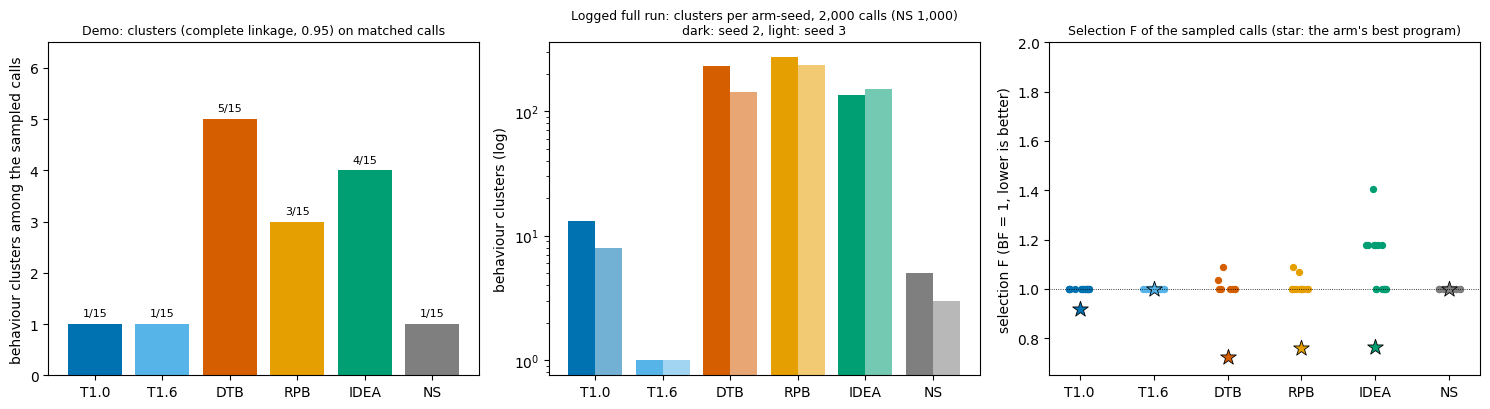

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
ax = axes[0]
arms = AN.ALL_ARMS
ax.bar(arms, [CLUSTERS[a]["clusters"] for a in arms], color=[COL[a] for a in arms])
for i, a in enumerate(arms):
    ax.text(i, CLUSTERS[a]["clusters"] + 0.15, f"{CLUSTERS[a]['clusters']}/{CLUSTERS[a]['calls']}", ha="center", fontsize=8)
ax.set_ylim(0, 1.2 * max(CLUSTERS[a]["clusters"] for a in arms) + 0.5)
ax.set_ylabel("behaviour clusters among the sampled calls")
ax.set_title("Demo: clusters (complete linkage, 0.95) on matched calls", fontsize=9)
ax = axes[1]
x = np.arange(len(arms))
for k, S in enumerate((2, 3)):
    vals = [logged["clusters_per_arm_seed"][f"S{S}-{a}"]["clusters"] for a in arms]
    ax.bar(x + (k - 0.5) * 0.4, vals, 0.4, color=[COL[a] for a in arms], alpha=1.0 if S == 2 else 0.55,
           label=f"seed {S}")
ax.set_xticks(x)
ax.set_xticklabels(arms)
ax.set_yscale("log")
ax.set_ylabel("behaviour clusters (log)")
ax.set_title("Logged full run: clusters per arm-seed, 2,000 calls (NS 1,000)\ndark: seed 2, light: seed 3", fontsize=9)
ax = axes[2]
for i, a in enumerate(arms):
    Fs = [e["F"] for ex, row, e in ROWS if row["arm"] == a and e["valid"] and ex["role"] == "matched_window_sample"]
    ax.scatter(np.full(len(Fs), i) + np.random.default_rng(i).uniform(-0.15, 0.15, len(Fs)), Fs, color=COL[a], s=18)
    ax.scatter([i], [BEST[a]["e"]["F"]], marker="*", s=140, color=COL[a], edgecolors="k", linewidths=0.6)
ax.axhline(1.0, color="k", lw=0.6, ls=":")
ax.set_xticks(range(len(arms)))
ax.set_xticklabels(arms)
ax.set_ylim(0.65, 2.0)
ax.set_ylabel("selection F (BF = 1, lower is better)")
ax.set_title("Selection F of the sampled calls (star: the arm's best program)", fontsize=9)
plt.tight_layout()
plt.show()

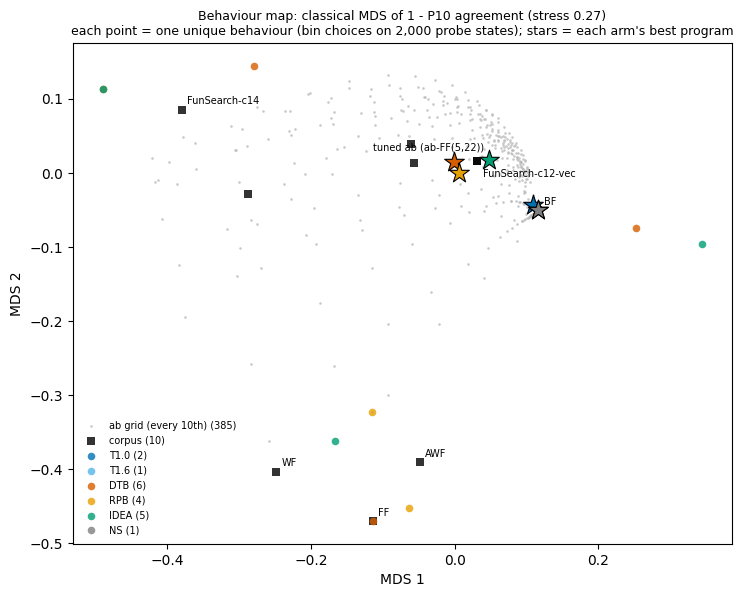

In [31]:
pts, lab = [], []
for arm in AN.ALL_ARMS:
    vecs, kept = AN.offspring_vectors([e for ex, row, e in ROWS if row["arm"] == arm], dec)
    for v in CL.unique_with_counts(vecs)[0]:
        pts.append(v)
        lab.append(arm)
named = [n for n, e in CORPUS.items() if e["p10"] is not None]
for n in named:
    pts.append(CORPUS[n]["p10"])
    lab.append("corpus")
for v in AB_DEC:
    pts.append(v)
    lab.append(f"ab grid (every {AB_STRIDE}th)")
P_ = np.stack(pts)
A_ = CL.agreement_matrix(P_, P_)
D_ = 1 - (A_ + A_.T) / 2
np.fill_diagonal(D_, 0)
X_, stress = classical_mds(D_)
fig, ax = plt.subplots(figsize=(8.5, 6.5))
style = {"corpus": ("k", "s", 36), f"ab grid (every {AB_STRIDE}th)": ("#bbbbbb", ".", 14)}
for g in [f"ab grid (every {AB_STRIDE}th)", "corpus"] + AN.ALL_ARMS:
    ii = [i for i, x in enumerate(lab) if x == g]
    c, m, s = style.get(g, (COL.get(g, "b"), "o", 30))
    ax.scatter(X_[ii, 0], X_[ii, 1], c=c, marker=m, s=s, label=f"{g} ({len(ii)})", alpha=0.8, linewidths=0)
offsets = {"FunSearch-c12-vec": (4, -11), f"tuned ab ({tuned_logged['name']})": (-30, 9)}
for n in ("BF", "FF", "WF", "AWF", "FunSearch-c14", "FunSearch-c12-vec", f"tuned ab ({tuned_logged['name']})"):
    i = len(pts) - len(AB_DEC) - len(named) + named.index(n)
    ax.annotate(n, X_[i], fontsize=7, xytext=offsets.get(n, (4, 4)), textcoords="offset points")
for arm, b in BEST.items():
    i = next(i for i, (x, v) in enumerate(zip(lab, pts)) if x == arm and np.array_equal(v, dec[b["e"]["probe_row"]]))
    ax.scatter(*X_[i], marker="*", s=220, c=COL[arm], edgecolors="k", linewidths=0.8)
ax.set_title(f"Behaviour map: classical MDS of 1 - P10 agreement (stress {stress:.2f})\n"
             "each point = one unique behaviour (bin choices on 2,000 probe states); stars = each arm's best program",
             fontsize=9)
ax.set_xlabel("MDS 1")
ax.set_ylabel("MDS 2")
ax.legend(frameon=False, fontsize=7, loc="best")
plt.show()

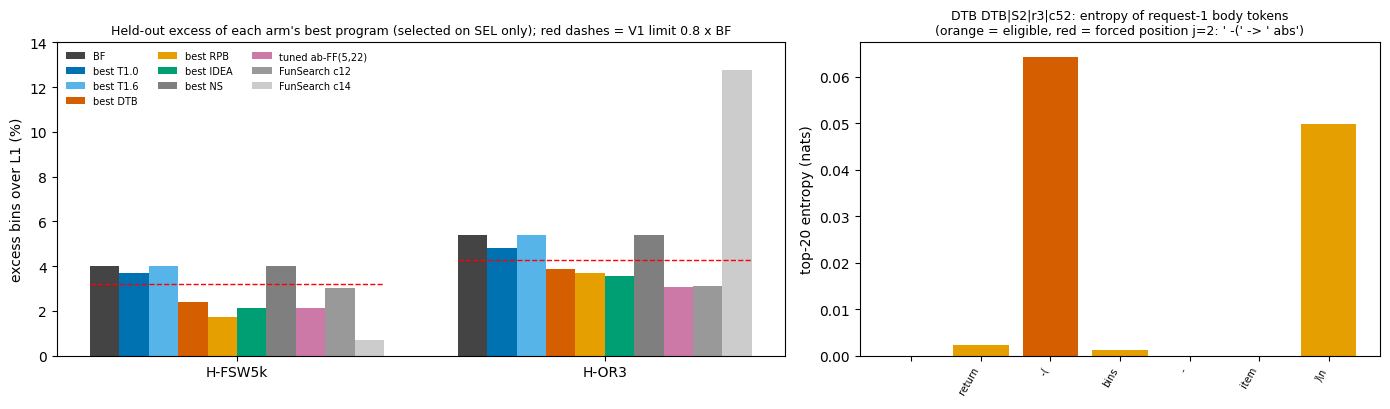

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw={"width_ratios": [1.4, 1]})
ax = axes[0]
rows = [("BF", {s: bf[s]["excess"] for s in HELDOUT_SETS}, "#444444")]
rows += [(f"best {a}", BEST[a]["excess"], COL[a]) for a in AN.ALL_ARMS]
rows += [(f"tuned {tuned_logged['name']}", ta["heldout_excess"], "#CC79A7"),
         ("FunSearch c12", CORPUS["FunSearch-c12-vec"]["heldout_excess"], "#999999"),
         ("FunSearch c14", CORPUS["FunSearch-c14"]["heldout_excess"], "#cccccc")]
w = 0.8 / len(rows)
for i, (name, exc, col) in enumerate(rows):
    ax.bar(np.arange(len(HELDOUT_SETS)) + i * w, [100 * exc[s] for s in HELDOUT_SETS], w, label=name, color=col)
for k, s in enumerate(HELDOUT_SETS):
    if s in v1["limits"]:
        ax.hlines(100 * v1["limits"][s], k - w / 2, k + 0.8 - w / 2, colors="r", linestyles="--", lw=1)
ax.set_xticks(np.arange(len(HELDOUT_SETS)) + 0.4 - w / 2)
ax.set_xticklabels(HELDOUT_SETS)
ax.set_ylabel("excess bins over L1 (%)")
ax.set_ylim(0, 14)
ax.set_title("Held-out excess of each arm's best program (selected on SEL only); red dashes = V1 limit 0.8 x BF", fontsize=9)
ax.legend(frameon=False, fontsize=7, ncol=3)
ax = axes[1]
b = SHOW_BRANCH
br, ex = b["plan"], b["ex"]
H = np.array(br["H"])
toks = [tt.text(t) for t in ex["r1_ids"][:len(H)]]
cols = ["#D55E00" if t == br["j"] else ("#E69F00" if t in br["E"] else "#cccccc") for t in range(len(H))]
ax.bar(np.arange(len(H)), H, color=cols)
ax.set_xticks(np.arange(len(H)))
ax.set_xticklabels([repr(s)[1:-1] for s in toks], rotation=60, fontsize=7, ha="right")
ax.set_ylabel("top-20 entropy (nats)")
ax.set_title(f"DTB {b['label']}: entropy of request-1 body tokens\n(orange = eligible, red = forced position j={br['j']}: "
             f"{br['gen_j_text']!r} -> {br['forced_text']!r})", fontsize=9)
plt.tight_layout()
plt.show()